# Линейная алгебра, математический анализ и теория вероятностей

Математические операции позволяют описывать наборы признаков, измерять изменения функций и учитывать случайность. **Линейная алгебра** работает с векторами и матрицами, **математический анализ** — с изменением и накоплением величин, **теория вероятностей** — со случайными событиями и величинами.

В каждом разделе формулы сопровождаются числовыми разборами и выполненным кодом. Все данные создаются внутри ноутбука. Выводы и графики сохранены, поэтому материал можно читать без запуска Python. При повторном запуске ячейки выполняются сверху вниз. Зависимости: NumPy и Matplotlib; специальных библиотек машинного обучения здесь нет.

Предварительное знание Python не требуется. Перед каждым блоком кода описано, что он вычисляет; после результатов разобраны конструкции языка и функции. У формул поясняются обозначения и шаги вычисления. Имена переменных из предыдущих ячеек сохраняются в памяти, поэтому при повторном запуске важен порядок ячеек.

**Содержание**

- [Обозначения и среда вычислений](#notation)
- [1. Линейная алгебра](#linear-algebra)
- [2. Математический анализ](#calculus)
- [3. Теория вероятностей](#probability)
- [4. Один пример, объединяющий три раздела](#connection)

<a id="notation"></a>
## Обозначения и среда вычислений

Буква в формуле обозначает число, вектор или другой объект. Её смысл задаётся рядом с формулой. Равенство утверждает, что выражения слева и справа имеют одинаковое значение. Ниже приведены базовые знаки, используемые в материале.

| Запись | Как читать и вычислять |
|---|---|
| $a+b$, $a-b$ | сложение и вычитание: $2+3=5$, $5-2=3$ |
| $ab$, $a\cdot b$ | умножение: отсутствие знака между буквами обычно означает произведение; $2x=2\cdot x$ |
| $\frac ab$ | разделить числитель $a$ на знаменатель $b$; $b\ne0$ |
| $(a+b)c$ | сначала вычислить сумму в скобках, затем умножить на $c$ |
| $x^2$, $x^3$, $x^n$ | степень: $x^2=x\cdot x$; верхний индекс здесь показывает число множителей |
| $\sqrt{x}$ | неотрицательный квадратный корень: $\sqrt9=3$, поскольку $3^2=9$ |
| $\lvert x\rvert$ | модуль — расстояние числа от нуля: $\lvert-3\rvert=3$ |
| $=$, $\ne$, $\approx$ | равно, не равно, приблизительно равно |
| $<$, $>$, $\le$, $\ge$ | меньше, больше, не больше, не меньше; например, $0\le p\le1$ |
| $x\in\mathbb{R}$ | $x$ принадлежит множеству вещественных чисел: допустимы целые, дробные и отрицательные значения |
| $\mathbf{x}\in\mathbb{R}^d$ | вектор из $d$ чисел; жирное начертание помогает отличить вектор от скаляра |
| $A\in\mathbb{R}^{n\times d}$ | матрица: $n$ строк и $d$ столбцов; $n\times d$ здесь обозначает размер |
| $x_i$, $a_{ij}$ | нижние индексы выбирают координату или элемент: $a_{ij}$ — строка $i$, столбец $j$ |
| $\sum_{i=1}^n x_i$ | сложить $x_1,x_2,\ldots,x_n$; $i$ — меняющийся номер слагаемого |
| $A^\top$, $\mathbf{x}^\top$ | транспонирование: строки и столбцы меняются местами; $\top$ здесь не степень |

Например, при $\mathbf{x}=(2,5,3)^\top$ сумма координат читается так:

$$\sum_{i=1}^{3}x_i=x_1+x_2+x_3=2+5+3=10.$$

Под знаком суммы написано, что первый номер — $i=1$, над ним — что последний номер равен 3. Многоточие означает продолжение того же правила. Одной буквой $i$ можно описать действие сразу для всех координат.

В тексте десятичные дроби записаны через запятую: $0{,}5$. В коде Python для той же дроби нужна точка: `0.5`. Запятая в Python обычно разделяет элементы или аргументы. В формулах номера обычно начинаются с **1**, в Python — с **0**. Векторы в формулах считаются столбцами, если не указано другое.

Обозначения производных, интегралов и вероятностей вводятся по мере появления. Одна буква в разных самостоятельных примерах может иметь разный смысл: этот смысл всегда задаётся в соответствующем разделе.

Первый блок подключает средства для вычислений и рисунков, настраивает вид результатов и показывает версии используемых программ. Числовых данных пока нет: после выполнения этой ячейки имена библиотек будут доступны всем следующим ячейкам ноутбука.

In [1]:
%matplotlib inline

from math import comb
from statistics import NormalDist
import sys

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    'figure.figsize': (8.5, 4.5),
    'figure.dpi': 110,
    'figure.constrained_layout.use': True,
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.2,
    'axes.prop_cycle': matplotlib.cycler(
        color=['#176B87', '#DC7B34', '#408060', '#8B5FA8']
    ),
})

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)

Python: 3.13.13
NumPy: 2.4.6
Matplotlib: 3.10.9


**Разбор кода.** Python исполняет инструкции сверху вниз. Ячейка — отдельный блок программы в Jupyter; её результат отображается ниже. `Shift+Enter` выполняет ячейку и переходит к следующей. Имена и настройки остаются в памяти работающего ядра — процесса Python, обслуживающего ноутбук.

- `%matplotlib inline` — специальная команда Jupyter: рисунки будут показаны прямо под ячейкой. Знак `%` в начале этой строки обозначает команду среды, а не обычную инструкцию Python.
- `import sys` подключает модуль `sys` с информацией о Python. Модуль — готовый набор средств. `import matplotlib` подключает библиотеку рисования. Подключение библиотеки не означает её установку: она уже должна быть доступна в среде.
- `import numpy as np` подключает NumPy и даёт ей короткое имя `np`. Часть `as` означает «использовать под именем». `import matplotlib.pyplot as plt` аналогично даёт имя `plt` набору функций построения графиков.
- `from math import comb` берёт функцию `comb` из модуля `math`; далее она вызывается без `math.`. `from statistics import NormalDist` подключает средство описания нормального распределения. Они понадобятся в разделе вероятностей.
- Точка выбирает часть объекта: в `np.set_printoptions` это функция библиотеки, в `sys.version` — хранящееся значение. **Функция** выполняет действие, её **вызов** записывается с круглыми скобками. Внутри скобок передаются **аргументы** — исходные данные или настройки вызова. Запятые разделяют аргументы.
- `np.set_printoptions(precision=4, suppress=True)` задаёт вид вывода массивов: `precision=4` ограничивает число знаков после точки в выбранном формате, `suppress=True` по возможности выводит малые числа обычными дробями. Эти настройки не округляют сами хранящиеся данные.
- В записи `имя=значение` **внутри вызова** слева указано имя параметра. Это передача настройки, а не сравнение. `True` и `False` — логические значения «истина» и «ложь»; регистр букв важен. Числа `4`, `110` — целые; `8.5`, `0.2` — дробные. Дробная часть в коде отделяется точкой.
- Текст в одинарных или двойных кавычках — **строка**, то есть текстовое значение. Кавычки ограничивают текст и сами в результат не включаются. Например, `'DejaVu Sans'` — название шрифта, а `'font.size'` — текстовый ключ настройки, а не обращение через точку.
- `{...}` в `plt.rcParams.update({...})` создаёт **словарь**: набор пар `ключ: значение`. Двоеточие отделяет ключ от значения, запятые разделяют пары. Метод `.update(...)` добавляет или меняет настройки в `plt.rcParams`. **Метод** — функция, связанная с объектом, к которой обращаются через точку.
- `(8.5, 4.5)` — **кортеж**, упорядоченная группа из двух значений: ширина и высота рисунка в дюймах. Квадратные скобки `[...]` создают **список**, например набор цветов. У списков и кортежей элементы сохраняют порядок; ниже их значения часто передаются функциям.
- `'figure.figsize'` задаёт размер рисунка, `'figure.dpi'` — разрешение, `'figure.constrained_layout.use'` включает автоматическое размещение подписей. `'font.family'` выбирает шрифт с русскими буквами, `'font.size'` — его размер в пунктах.
- `'axes.spines.top'` и `'axes.spines.right'` со значением `False` убирают верхнюю и правую рамки. `'axes.grid': True` включает сетку, `'grid.alpha': 0.2` делает её полупрозрачной: 0 означает полную прозрачность, 1 — непрозрачность.
- `matplotlib.cycler(color=[...])` задаёт последовательность цветов для графиков. Строки вида `'#176B87'` — шестнадцатеричные коды цвета; знак `#` **внутри строки** здесь часть цветового кода. Настройка `'axes.prop_cycle'` сохраняет эту последовательность.
- `print(...)` — встроенная функция вывода. Например, `print('NumPy:', np.__version__)` печатает текст и значение версии, разделённые пробелом. Имена `__version__` — готовые атрибуты библиотек, их нужно писать с двумя подчёркиваниями с каждой стороны.
- В `sys.version.split()[0]` сначала берётся текст версии Python, `.split()` разбивает его по пробельным символам на список частей, `[0]` выбирает первую часть. Нумерация начинается с нуля. Пустые скобки у `.split()` означают вызов без явно переданных аргументов.

Отступы внутри круглых, квадратных и фигурных скобок помогают читать длинную инструкцию; она может занимать несколько строк. Пустая строка отделяет части программы для удобства чтения и ничего не вычисляет. Вывод трёх версий подтверждает, что подключение завершилось.

<a id="linear-algebra"></a>
## 1. Линейная алгебра

### 1.1. Скаляр, вектор, матрица и форма массива

**Скаляр** — одно число, например масса посылки $2$ кг. **Вектор** — упорядоченный набор чисел. Посылку можно описать двумя признаками: массой и числом упаковочных мест:

$$\mathbf{x}=\begin{bmatrix}2\\1\end{bmatrix}\in\mathbb{R}^2.$$

**Матрица** объединяет несколько векторов. В следующем примере строка соответствует отправлению, столбец — признаку:

$$X=\begin{bmatrix}2&1\\5&2\\3&2\end{bmatrix}\in\mathbb{R}^{3\times2}.$$

В NumPy `.shape` показывает длины осей массива. Форма `(3, 2)` означает три строки и два столбца. Массив формы `(2,)` — одномерный: у него нет отдельной оси строки или столбца. Поэтому транспонирование такого массива **не превращает его в столбец**; для явного столбца нужна форма `(2, 1)`.

Массив с тремя и более осями часто называют тензором. Для операций этого занятия достаточно векторов и матриц.

**Чтение записи.** Вектор $\mathbf{x}$ содержит две координаты: первая — 2, вторая — 1. Квадратные скобки в математической записи объединяют числа в один вектор; запись столбцом показывает его ориентацию. В $\mathbb{R}^2$ верхнее число 2 обозначает размерность пространства, а не возведение в квадрат.

В матрице $X$ первая строка $(2,1)$ описывает первое отправление, вторая $(5,2)$ — второе, третья $(3,2)$ — третье. Число 3 в размере $3\times2$ — количество строк, число 2 — количество столбцов. Например, $x_{21}=5$: берётся вторая строка и первый столбец. Заглавная $X$ здесь обозначает таблицу, строчная жирная $\mathbf{x}$ — одно отправление.

Следующий блок записывает признаки одного отправления и трёх отправлений в массивы NumPy. Затем выводит их формы, превращает одномерный массив в столбец и показывает, как выбрать целую строку или один столбец таблицы.

In [2]:
shipment = np.array([2.0, 1.0])
shipments = np.array([
    [2.0, 1.0],
    [5.0, 2.0],
    [3.0, 2.0],
])

print('Вектор отправления:', shipment)
print('Его форма:', shipment.shape)
print('После .T:', shipment.T.shape)
print('Явный столбец:\n', shipment.reshape(-1, 1))
print('Форма матрицы:', shipments.shape)
print('Второе отправление:', shipments[1])
print('Массы всех отправлений:', shipments[:, 0])

Вектор отправления: [2. 1.]
Его форма: (2,)
После .T: (2,)
Явный столбец:
 [[2.]
 [1.]]
Форма матрицы: (3, 2)
Второе отправление: [5. 2.]
Массы всех отправлений: [2. 5. 3.]


**Разбор кода.**

- `shipment = ...` создаёт переменную с именем `shipment` («отправление»). Переменная — имя для значения. Знак `=` означает **присваивание**: сначала вычисляется правая часть, затем результат сохраняется под именем слева. Это отличается от проверки равенства, для которой в Python используется `==`.
- `np.array([2.0, 1.0])` превращает список из двух дробных чисел в массив NumPy — объект для числовых вычислений. Внешние круглые скобки относятся к вызову функции, внутренние квадратные — к списку данных. Дробная запись позволяет хранить значения как числа с плавающей точкой, допускающие нецелые результаты.
- В `shipments = np.array([[...], [...], [...]])` каждый внутренний список задаёт строку, а внешний собирает три строки в таблицу. У всех строк одинаковая длина. Запятая после последней строки допустима и не добавляет пустой элемент.
- `shipment.shape` — атрибут формы. Результат `(2,)` — кортеж из одного числа; запятая отличает его от просто числа в скобках. `shipments.shape` даёт `(3, 2)`. В отличие от методов, при чтении атрибута `.shape` скобки вызова не нужны.
- `shipment.T` — транспонированный массив. Последующее `.shape` читает его форму. Для одномерного массива она не меняется, что видно в выводе.
- `shipment.reshape(-1, 1)` вызывает метод изменения формы. Число `1` задаёт один столбец, `-1` просит NumPy вычислить оставшийся размер по числу элементов; получается две строки. Сам `shipment` здесь не переназначается и сохраняет прежнюю форму.
- `shipments[1]` выбирает вторую строку: номера строк равны 0, 1, 2. `shipments[:, 0]` использует два индекса через запятую: `:` берёт **все строки**, `0` — первый столбец. Здесь квадратные скобки после имени означают выбор элементов, а не создание нового списка.
- `print('Текст:', значение)` выводит подпись и соответствующий объект. Последовательность `\n` внутри строки означает перенос строки, поэтому столбец печатается ниже подписи. В числовом выводе `2.` означает то же значение, что `2.0`.

Формы `(2,)` и `(2, 1)` описывают одни и те же два числа, но задают разную структуру для последующих операций.

### 1.2. Операции с векторами и скалярное произведение

Векторы одинаковой размерности складываются поэлементно. Умножение на скаляр изменяет каждую координату:

$$\mathbf{a}+\mathbf{b}=(a_1+b_1,\ldots,a_d+b_d)^\top,\qquad c\mathbf{a}=(ca_1,\ldots,ca_d)^\top.$$

**Скалярное произведение** двух векторов возвращает одно число:

$$\mathbf{x}^\top\mathbf{w}=\sum_{j=1}^d x_jw_j.$$

Для отправления введём тарифы $\mathbf{w}=(100,50)^\top$: 100 рублей за килограмм и 50 рублей за упаковочное место. Тогда

$$\mathbf{x}^\top\mathbf{w}=2\cdot100+1\cdot50=250\text{ рублей}.$$

Единицы измерения важны: каждое произведение в сумме должно выражать одну и ту же величину. Если есть фиксированный сбор $b=30$ рублей, итоговая стоимость равна $\mathbf{x}^\top\mathbf{w}+b=280$ рублей.

В NumPy `*` умножает элементы, а `@` вычисляет скалярное или матричное произведение. У этих операций разные результаты.

**Чтение формул и расчёт.** В $\mathbf{a}+\mathbf{b}$ складываются только координаты с одинаковым номером: для $(1,2)^\top$ и $(3,-1)^\top$ получаем $(1+3,2+(-1))^\top=(4,1)^\top$. Умножение $2\mathbf{a}$ даёт $(2\cdot1,2\cdot2)^\top=(2,4)^\top$. Буква $c$ в общей формуле означает одно число, а $d$ — число координат.

В $\sum_{j=1}^d x_jw_j$ нижний индекс $j$ последовательно принимает значения от 1 до $d$. Сначала умножаются координаты с одинаковым номером, затем складываются произведения. При $d=2$ это $x_1w_1+x_2w_2$. Знак $\top$ поворачивает вектор-столбец $\mathbf{x}$ в строку, чтобы произведение строки на столбец вернуло одно число.

В $\mathbf{x}^\top\mathbf{w}+b$ сначала считается $2\cdot100+1\cdot50=250$, затем добавляется $b=30$: получается 280 рублей. Буква $b$ здесь обозначает фиксированный сбор и отличается от вектора $\mathbf{b}$ в формуле сложения.

Теперь массив тарифов сопоставляется признакам уже созданного отправления. Блок отдельно покажет вклады массы и упаковки, их сумму и стоимость со сбором, а затем на двух коротких векторах продемонстрирует сложение и умножение на число.

In [3]:
tariffs = np.array([100.0, 50.0])
fixed_fee = 30.0

print('Вклады отдельных признаков:', shipment * tariffs)
print('Сумма вкладов:', np.sum(shipment * tariffs))
print('Скалярное произведение:', shipment @ tariffs)
print('Стоимость со сбором:', shipment @ tariffs + fixed_fee)

a = np.array([1.0, 2.0])
b = np.array([3.0, -1.0])
print('a + b =', a + b)
print('2a =', 2 * a)

Вклады отдельных признаков: [200.  50.]
Сумма вкладов: 250.0
Скалярное произведение: 250.0
Стоимость со сбором: 280.0
a + b = [4. 1.]
2a = [2. 4.]


**Разбор кода.**

- `tariffs = np.array([100.0, 50.0])` сохраняет два тарифа в массив; `fixed_fee = 30.0` сохраняет одно число, фиксированный сбор. Имена переменных выбирает автор, но далее их написание должно точно совпадать; подчёркивание соединяет слова без пробела.
- `shipment` уже создан в предыдущем примере. Повторно задавать его не нужно, пока ядро не перезапущено. При запуске этой ячейки без предыдущих Python не найдёт это имя.
- `shipment * tariffs` — поэлементное умножение массивов одинаковой длины: получается `[200., 50.]`. Знак `*` между обычными числами также означает умножение.
- `np.sum(...)` складывает все элементы переданного массива. Во вложенной записи `np.sum(shipment * tariffs)` сначала вычисляется произведение, затем функция получает его результат.
- `shipment @ tariffs` — скалярное произведение двух одномерных массивов: результат одно число 250. Знак `@` не совпадает со знаком `*` и не обозначает адрес или электронную почту.
- В `shipment @ tariffs + fixed_fee` сначала считается произведение, затем добавляется сбор. Обычные круглые скобки при необходимости задают другой порядок вычислений.
- В `np.array([3.0, -1.0])` знак `-` перед числом делает его отрицательным. `a + b` складывает массивы поэлементно, а `2 * a` умножает каждую координату на 2. Для массивов NumPy это числовые операции; для обычных списков Python правила другие.
- В строках `print('a + b =', a + b)` текст внутри кавычек служит подписью, а выражение **после запятой** действительно вычисляется. Знаки `+` и `=` внутри подписи сами ничего не считают.

Два способа получить 250 совпадают: сумма поэлементных вкладов и скалярное произведение описывают одно вычисление. Прибавление 30 даёт 280.

### 1.3. Длина, расстояние и угол

**Евклидова норма** — длина вектора, обобщающая теорему Пифагора:

$$\lVert\mathbf{u}\rVert_2=\sqrt{\sum_{j=1}^d u_j^2}.$$

**Евклидово расстояние** между двумя точками — длина их разности:

$$d(\mathbf{u},\mathbf{v})=\lVert\mathbf{u}-\mathbf{v}\rVert_2.$$

Для ненулевых векторов скалярное произведение связано с углом:

$$\cos\theta=\frac{\mathbf{u}^\top\mathbf{v}}{\lVert\mathbf{u}\rVert_2\lVert\mathbf{v}\rVert_2}.$$

Косинус равен 1 для совпадающих направлений, 0 для перпендикулярных и −1 для противоположных. Он характеризует направление, а расстояние учитывает и длины. Для нулевого вектора эта формула косинуса не определена.

Пусть $\mathbf{u}=(3,4)^\top$, $\mathbf{v}=(4,3)^\top$. Тогда обе нормы равны 5, расстояние равно $\sqrt{2}$, скалярное произведение — 24, а косинус — $24/25=0{,}96$. На рисунке координаты имеют одинаковые единицы. Для разнородных признаков выбор единиц меняет геометрический смысл расстояний и углов.

**Чтение формул и расчёт.** Двойные черты $\lVert\mathbf{u}\rVert_2$ обозначают норму вектора; нижний индекс 2 указывает на использование квадратов координат. Для $\mathbf{u}=(3,4)^\top$: $\sqrt{3^2+4^2}=\sqrt{9+16}=5$. Во второй формуле $d(\mathbf{u},\mathbf{v})$ — имя функции расстояния с двумя входами, а не произведение буквы $d$ на скобку.

Для расстояния сначала находится разность $(3-4,4-3)^\top=(-1,1)^\top$, затем длина: $\sqrt{(-1)^2+1^2}=\sqrt2$. Скобки в $(-1)^2$ показывают, что в квадрат возводится всё отрицательное число; результат равен 1.

Греческая буква $\theta$ («тета») обозначает угол между векторами. $\cos\theta$ — косинус этого угла: здесь он находится как отношение скалярного произведения к произведению длин. Числитель равен $3\cdot4+4\cdot3=24$, знаменатель — $5\cdot5=25$. Получается $0{,}96$; соответствующий угол примерно $16{,}26^\circ$. При нулевой длине знаменатель стал бы нулём, поэтому такой случай исключён.

В этом блоке создаются два геометрических вектора, рассчитываются их длины, расстояние, косинус и угол. Затем на одной координатной плоскости строятся две стрелки и соединяющий их концы отрезок; изображение помогает сопоставить числа с геометрией.

Длины: 5.0 и 5.0
Расстояние: 1.4142
Косинус: 0.9600; угол: 16.26°


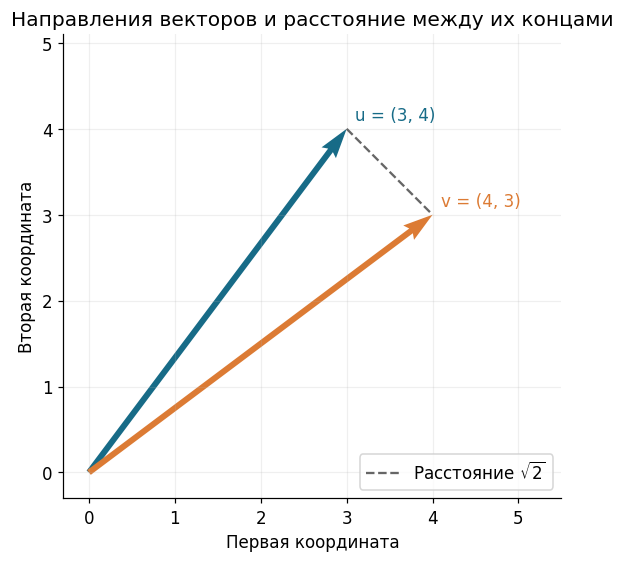

In [4]:
u = np.array([3.0, 4.0])
v = np.array([4.0, 3.0])
norm_u = np.linalg.norm(u)
norm_v = np.linalg.norm(v)
distance = np.linalg.norm(u - v)
cosine = (u @ v) / (norm_u * norm_v)
angle = np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))

print(f'Длины: {norm_u:.1f} и {norm_v:.1f}')
print(f'Расстояние: {distance:.4f}')
print(f'Косинус: {cosine:.4f}; угол: {angle:.2f}°')

fig, ax = plt.subplots(figsize=(6.2, 5.0))
for vector, label, color in [(u, 'u = (3, 4)', '#176B87'),
                              (v, 'v = (4, 3)', '#DC7B34')]:
    ax.quiver(0, 0, *vector, angles='xy', scale_units='xy', scale=1,
              color=color, width=0.012)
    ax.text(vector[0] + 0.1, vector[1] + 0.1, label, color=color)
ax.plot([u[0], v[0]], [u[1], v[1]], '--', color='#666666',
        label=r'Расстояние $\sqrt{2}$')
ax.set(xlim=(-0.3, 5.5), ylim=(-0.3, 5.1),
       xlabel='Первая координата', ylabel='Вторая координата',
       title='Направления векторов и расстояние между их концами')
ax.set_aspect('equal')
ax.legend(loc='lower right')
plt.show()

**Разбор вычислений.**

- `u` и `v` — имена массивов из двух координат; `norm_u`, `norm_v`, `distance`, `cosine`, `angle` сохраняют отдельные результаты. Каждое присваивание `=` вычисляет свою правую часть, а не утверждает математическую тождественность всех этих величин.
- `np.linalg` — часть NumPy для линейной алгебры, `.norm(u)` вычисляет евклидову норму переданного вектора. В `np.linalg.norm(u - v)` сначала создаётся разность координат, затем находится её длина.
- Операторы `@`, `*`, `/` в строке `cosine = ...` соответственно считают скалярное произведение, произведение длин и их отношение. Скобки в знаменателе требуют сначала перемножить длины.
- `np.clip(cosine, -1.0, 1.0)` ограничивает значение диапазоном от −1 до 1, защищая обратную тригонометрическую функцию от небольшого выхода за границы из-за округления. `np.arccos(...)` по косинусу восстанавливает угол в радианах; `np.degrees(...)` переводит его в градусы. Вложенные вызовы вычисляются изнутри наружу.
- Буква `f` перед кавычкой создаёт **форматируемую строку**. В `f'Длины: {norm_u:.1f}'` выражение внутри `{...}` заменяется значением переменной. После двоеточия `.1f` задаёт одну цифру после точки; `.4f` — четыре, `.2f` — две. Округляется только текст вывода. Знак `°` — обычный символ в строке.

**Разбор построения рисунка.**

- `fig, ax = plt.subplots(figsize=(6.2, 5.0))` создаёт рисунок и одну область рисования. Функция возвращает два объекта; запись двух имён через запятую **распаковывает** их по порядку. `fig` — рисунок целиком, `ax` — область с осями. `figsize` передаёт ширину и высоту.
- `for vector, label, color in [...]:` — цикл. Он последовательно берёт каждый элемент списка после `in`. Каждый элемент здесь кортеж из вектора, подписи и цвета; три значения распаковываются в три имени. Двоеточие начинает тело цикла, а строки с четырьмя пробелами отступа выполняются для каждого элемента. После возврата к левому краю цикл закончен.
- `ax.quiver(0, 0, *vector, ...)` рисует стрелку. Два нуля — начальная точка. Запись `*vector` **внутри аргументов вызова** распаковывает две координаты: для `u` это то же, что передать `3.0, 4.0`. Здесь `*` не умножает, потому что стоит перед одним аргументом.
- У `quiver` параметры `angles='xy'`, `scale_units='xy'`, `scale=1` сохраняют смысл координат и длины стрелок в единицах осей. `color=color` передаёт в параметр `color` значение переменной с тем же именем; слева имя параметра, справа имя переменной. `width` задаёт толщину стрелки.
- `ax.text(x, y, текст, ...)` размещает подпись. `vector[0]` и `vector[1]` выбирают координаты, а прибавление `0.1` немного отодвигает текст от конца стрелки.
- `ax.plot([u[0], v[0]], [u[1], v[1]], '--', ...)` строит линию по двум точкам. Первый список содержит обе горизонтальные координаты, второй — обе вертикальные. `'--'` выбирает пунктир. `label` задаёт текст для легенды, `color` — цвет.
- Префикс `r` в `r'Расстояние $\sqrt{2}$'` создаёт **сырую строку**, сохраняющую обратные косые черты. Символы `$...$` внутри подписи включают математическое оформление Matplotlib; `\sqrt{2}` рисует корень. Это текст для рисунка, а не вычисление корня в Python.
- `ax.set(...)` задаёт несколько настроек: `xlim`, `ylim` — границы осей, `xlabel`, `ylabel` — подписи, `title` — заголовок. Границы передаются кортежами из двух чисел.
- `ax.set_aspect('equal')` делает единичные отрезки по обеим осям одинаковыми на экране. `ax.legend(loc='lower right')` показывает легенду справа внизу. `plt.show()` выводит готовый рисунок; пустые скобки всё равно нужны для вызова функции.

Длины 5 и 5 совпадают, расстояние примерно 1,4142, а угол примерно 16,26°. Небольшое расстояние между концами не означает полного совпадения направлений.

Два первых вызова `np.array(...)` создают массивы координат из списков. Вызовы `print(...)` перед рисунком выводят рассчитанные числа; массивы и сам график при этом не изменяются.

### 1.4. Матричное произведение и транспонирование

Для произведения $AB$ число столбцов $A$ должно совпадать с числом строк $B$:

$$\underbrace{A}_{n\times d}\underbrace{B}_{d\times k}=\underbrace{C}_{n\times k},\qquad c_{ij}=\sum_{r=1}^d a_{ir}b_{rj}.$$

Каждый элемент результата — скалярное произведение строки первой матрицы и столбца второй. Для всех отправлений сразу:

$$\mathbf{c}=X\mathbf{w}+b\mathbf{1}=\begin{bmatrix}280\\630\\430\end{bmatrix},$$

где $\mathbf{1}$ — вектор из единиц. В NumPy при сложении с числом сбор добавляется к каждому результату.

**Транспонирование** меняет строки и столбцы местами: $(X^\top)_{ij}=X_{ji}$. Например, из формы $(3,2)$ получается $(2,3)$.

Согласованность форм не гарантирует правильный смысл вычисления. В частности, `(3, 1) + (3,)` из-за правил расширения форм (*broadcasting*) даёт матрицу `(3, 3)`. При сложении двух векторов результатов их формы должны совпадать.

**Чтение формул и расчёт.** Буквы $n,d,k$ задают размеры матриц. Совпадающее $d$ показывает общую длину строки $A$ и столбца $B$. В $c_{ij}=\sum_{r=1}^d a_{ir}b_{rj}$ номера $i,j$ фиксируют искомое место в результате, а $r$ перебирает пары перемножаемых элементов. Например, элемент первой строки и первого столбца получается из первой строки $A$ и первого столбца $B$.

В формуле стоимости $X\mathbf{w}$ возвращает три числа: $2\cdot100+1\cdot50=250$, $5\cdot100+2\cdot50=600$, $3\cdot100+2\cdot50=400$. Вектор $\mathbf{1}=(1,1,1)^\top$, поэтому $b\mathbf{1}=(30,30,30)^\top$. После сложения получаем $\mathbf{c}=(280,630,430)^\top$.

В $(X^\top)_{ij}=X_{ji}$ номера меняются местами: элемент строки 1 и столбца 2 исходной матрицы становится элементом строки 2 и столбца 1 транспонированной. Скобки показывают, что сначала транспонируется вся матрица, затем выбирается элемент.

Следующий блок рассчитывает стоимость сразу всех трёх отправлений и выводит транспонированную таблицу. Затем сравнивает сложение столбца с одномерным массивом и сложение двух одинаково оформленных столбцов, чтобы показать влияние формы на результат.

In [5]:
costs = shipments @ tariffs + fixed_fee
print('Формы:', shipments.shape, '@', tariffs.shape, '→', costs.shape)
print('Стоимость всех отправлений:', costs)
print('Транспонированная матрица:\n', shipments.T)

# Две записи одного набора результатов согласуются после явного изменения формы.
costs_column = costs.reshape(-1, 1)
print('Столбец + одномерный массив:', (costs_column + costs).shape)
print('Столбец + столбец:', (costs_column + costs.reshape(-1, 1)).shape)

Формы: (3, 2) @ (2,) → (3,)
Стоимость всех отправлений: [280. 630. 430.]
Транспонированная матрица:
 [[2. 5. 3.]
 [1. 2. 2.]]
Столбец + одномерный массив: (3, 3)
Столбец + столбец: (3, 1)


**Разбор кода.**

- `costs = shipments @ tariffs + fixed_fee` использует три ранее заданных имени. Матричное произведение таблицы на вектор даёт массив трёх стоимостей, а прибавление одного числа добавляет сбор к каждой стоимости.
- Атрибуты `.shape` в первом `print` читают формы операндов и результата. Строки `'@'` и `'→'` здесь только разделяют их в выводе; реальное умножение было выполнено в предыдущей строке.
- `shipments.T` меняет местами две оси таблицы. Последовательность `\n` в подписи `print` переносит таблицу на следующую строку.
- `# ...` за пределами кавычек начинает **комментарий**. Python не исполняет текст от `#` до конца строки; он поясняет программу читателю. Здесь комментарий относится к двум вариантам формы результата.
- `costs.reshape(-1, 1)` создаёт представление в виде столбца. `costs_column` сохраняет его отдельно; исходное имя `costs` продолжает обозначать одномерный массив.
- В `(costs_column + costs).shape` сначала вычисляется выражение в скобках, затем читается форма результата. Массив `(3,)` при сложении со столбцом `(3, 1)` распространяется по другой оси, поэтому возникают девять попарных сумм в таблице `(3, 3)`.
- В последней строке `costs.reshape(-1, 1)` превращает и второй операнд в столбец. Складываются формы `(3, 1)` и `(3, 1)`, поэтому результат тоже столбец `(3, 1)`.

Проверка формы позволяет обнаружить ошибку даже тогда, когда Python не сообщает об исключении: оба сложения допустимы, но выполняют разные действия.

Матрица также задаёт **линейное преобразование**: $T(\mathbf{x})=A\mathbf{x}$. Оно сохраняет сложение и умножение на число. Добавление ненулевого смещения $\mathbf{b}$ даёт уже аффинное преобразование $A\mathbf{x}+\mathbf{b}$.

Порядок преобразований важен: в $AB\mathbf{x}$ сначала действует $B$, затем $A$. В общем случае $AB\ne BA$. Например, растяжение первой координаты вдвое и поворот на 90° дают разные результаты при перестановке.

**Чтение записи.** $T(\mathbf{x})$ — результат применения преобразования с именем $T$ к вектору $\mathbf{x}$. В $A\mathbf{x}+\mathbf{b}$ сначала выполняется матричное произведение, затем прибавляется вектор смещения. Нулевое смещение не меняет результат.

В $AB\mathbf{x}$ скобки можно поставить как $A(B\mathbf{x})$: сначала вектор преобразует $B$, затем получившийся результат — $A$. Перестановка матриц меняет сами действия. Для точки $(1,1)^\top$ поворот даёт $(-1,1)^\top$, после растяжения — $(-2,1)^\top$. При обратном порядке сначала получается $(2,1)^\top$, затем $(-1,2)^\top$.

В следующем блоке две матрицы задают растяжение и поворот точки. Одна и та же точка проходит оба преобразования в разном порядке; вывод показывает конечные координаты и проверяет, совпадают ли сами матрицы составных преобразований.

In [6]:
stretch = np.array([[2.0, 0.0], [0.0, 1.0]])
rotation = np.array([[0.0, -1.0], [1.0, 0.0]])
point = np.array([1.0, 1.0])

print('Сначала поворот, затем растяжение:', stretch @ rotation @ point)
print('Сначала растяжение, затем поворот:', rotation @ stretch @ point)
print('Матрицы произведений совпадают:', np.allclose(
    stretch @ rotation, rotation @ stretch
))

Сначала поворот, затем растяжение: [-2.  1.]
Сначала растяжение, затем поворот: [-1.  2.]
Матрицы произведений совпадают: False


**Разбор кода.**

- `np.array([[...], [...]])` создаёт матрицу из двух строк и двух столбцов. `stretch` хранит растяжение первой координаты, `rotation` — поворот на 90° против часовой стрелки, `point` — массив координат точки.
- Оператор `@` применён несколько раз. Выражения `stretch @ rotation @ point` и `rotation @ stretch @ point` различаются перестановкой первых двух массивов. Матричное умножение допускает перегруппировку скобок, но перестановка множителей в общем случае недопустима.
- `np.allclose(первый_массив, второй_массив)` сравнивает соответствующие элементы с небольшим численным допуском и возвращает одно логическое значение. Это удобнее строгого равенства для вычислений с дробными числами.
- Последний вызов `print` занимает несколько строк. Круглые скобки `np.allclose(...)` и внешние скобки `print(...)` должны закрыться каждая своей парой. Перенос внутри незакрытых скобок продолжает ту же инструкцию.

Результат `False` читается как «матрицы не совпадают в пределах допуска». Координаты `[-2., 1.]` и `[-1., 2.]` показывают это различие на конкретной точке.

### 1.5. Системы линейных уравнений и ранг

Система уравнений записывается как $A\mathbf{x}=\mathbf{b}$. Рассмотрим

$$\begin{cases}2x_1+x_2=5,\\x_1+3x_2=5.\end{cases}\qquad
A=\begin{bmatrix}2&1\\1&3\end{bmatrix},\quad\mathbf{b}=\begin{bmatrix}5\\5\end{bmatrix}.$$

Подстановка $\mathbf{x}=(2,1)^\top$ удовлетворяет обоим уравнениям. Для квадратной матрицы единственное решение существует тогда, когда её столбцы линейно независимы.

**Ранг** — число линейно независимых столбцов (оно равно числу линейно независимых строк). Матрица $n\times n$ полного ранга имеет ранг $n$. Её определитель отличен от нуля. Для матрицы $2\times2$:

$$\det\begin{bmatrix}a&b\\c&d\end{bmatrix}=ad-bc.$$

В данном примере $\det A=2\cdot3-1\cdot1=5$. Численно систему решает `np.linalg.solve`. Явно вычислять обратную матрицу для этого не требуется. Невязка $A\mathbf{x}-\mathbf{b}$ показывает, насколько найденный результат удовлетворяет исходным уравнениям.

**Чтение формул и расчёт.** Фигурная скобка у системы означает, что оба уравнения должны выполняться одновременно для одной пары $x_1,x_2$. В $A\mathbf{x}=\mathbf{b}$ матрица $A$ содержит коэффициенты при неизвестных, $\mathbf{x}$ — сами неизвестные, $\mathbf{b}$ — правые части.

Подстановка $(2,1)^\top$ даёт в первой строке $2\cdot2+1=5$, во второй $2+3\cdot1=5$. Найти эти значения вручную можно исключением: из первого уравнения $x_2=5-2x_1$; подстановка во второе даёт $x_1+3(5-2x_1)=5$, затем $-5x_1=-10$, откуда $x_1=2$ и $x_2=1$.

Запись $\det A$ читается «определитель матрицы $A$». В общей матрице $2\times2$ буквы $a,b,c,d$ — четыре отдельных числа. Формула $ad-bc$ означает произведение элементов главной диагонали минус произведение элементов другой диагонали. Невязка $A\mathbf{x}-\mathbf{b}$ — вектор разностей левых и правых частей, который для точного решения равен нулевому вектору.

Этот блок записывает коэффициенты системы и правые части в два массива, вычисляет решение и подставляет его обратно. Кроме координат решения выводятся ранг, определитель и невязка — величины, позволяющие связать численный ответ с разобранными условиями системы.

In [7]:
system_matrix = np.array([[2.0, 1.0], [1.0, 3.0]])
right_side = np.array([5.0, 5.0])
solution = np.linalg.solve(system_matrix, right_side)

print('Ранг:', np.linalg.matrix_rank(system_matrix))
print(f'Определитель: {np.linalg.det(system_matrix):.1f}')
print('Решение:', solution)
print('Невязка:', system_matrix @ solution - right_side)

Ранг: 2
Определитель: 5.0
Решение: [2. 1.]
Невязка: [0. 0.]


**Разбор кода.**

- `system_matrix` — матрица коэффициентов, `right_side` — вектор правых частей. В каждой строке матрицы порядок коэффициентов соответствует порядку неизвестных $x_1,x_2$.
- `np.linalg.solve(system_matrix, right_side)` получает два аргумента: матрицу и правую часть. Возвращённый массив сохраняется в `solution`; его элементы — значения неизвестных в том же порядке.
- `np.linalg.matrix_rank(...)` возвращает ранг, `np.linalg.det(...)` — определитель. Это две разные функции внутри части `linalg` библиотеки NumPy.
- В `f'Определитель: {np.linalg.det(system_matrix):.1f}'` внутри фигурных скобок можно написать целый вызов функции. Сначала вычисляется определитель, затем `.1f` оформляет его с одним знаком после точки.
- `system_matrix @ solution - right_side` сначала подставляет решение во все левые части с помощью `@`, затем поэлементно вычитает правые части с помощью `-`. Дополнительная функция для невязки не нужна.

Вывод `[2., 1.]` означает $x_1=2$, $x_2=1$. Невязка `[0., 0.]` подтверждает выполнение обоих уравнений для этой пары.

Два вызова `np.array(...)` в начале превращают вложенный список коэффициентов и список правых частей в числовые массивы. Каждый `print(...)` выводит одну строку проверки; внутри него может находиться как готовая переменная, так и выражение.

Если одна строка выражается через другую, часть уравнений не добавляет информации. Для

$$A_s=\begin{bmatrix}1&2\\2&4\end{bmatrix}$$

вторая строка вдвое больше первой, поэтому ранг равен 1. При $\mathbf{b}=(3,6)^\top$ решений бесконечно много: любое $x_2=t$ даёт $x_1=3-2t$. При $\mathbf{b}=(3,7)^\top$ решений нет: левые части требуют удвоения, а правые этому противоречат.

Это различие показывает **расширенная матрица** $[A\mid\mathbf{b}]$: если её ранг больше ранга $A$, система несовместна. В численных вычислениях ранг зависит от допуска: почти зависимые столбцы могут давать неустойчивые решения даже без точной зависимости.

**Чтение записи и расчёт.** Нижний индекс $s$ в $A_s$ — метка конкретной матрицы, а не номер её элемента. Вторая строка $(2,4)$ равна $2(1,2)$, поэтому независимая строка только одна. При правой части $(3,6)^\top$ оба уравнения сводятся к $x_1+2x_2=3$.

Буква $t$ — свободно выбираемое вещественное число. Запись $x_2=t$, $x_1=3-2t$ описывает все решения: при $t=0$ это $(3,0)$, при $t=1$ — $(1,1)$, и так далее. При правой части $(3,7)^\top$ второе уравнение после деления на 2 потребовало бы $x_1+2x_2=3{,}5$, что противоречит первому.

В $[A\mid\mathbf{b}]$ вертикальная черта означает приписанный справа столбец правых частей. Это обозначение расширенной матрицы, а не операция деления и не условная вероятность.

Здесь одна матрица проверяется с двумя разными правыми частями. Код по очереди добавляет каждую правую часть к матрице, сравнивает ранги и выводит текстовый вывод о числе решений. Поиск конкретного решения для вырожденной системы не выполняется.

In [8]:
singular_matrix = np.array([[1.0, 2.0], [2.0, 4.0]])
rank_matrix = np.linalg.matrix_rank(singular_matrix)
for values in ([3.0, 6.0], [3.0, 7.0]):
    augmented = np.column_stack((singular_matrix, values))
    rank_augmented = np.linalg.matrix_rank(augmented)
    conclusion = ('бесконечно много решений'
                  if rank_augmented == rank_matrix else 'решений нет')
    print(f'b = {values}: ранг A = {rank_matrix}, '
          f'ранг [A|b] = {rank_augmented}; {conclusion}')

b = [3.0, 6.0]: ранг A = 1, ранг [A|b] = 1; бесконечно много решений
b = [3.0, 7.0]: ранг A = 1, ранг [A|b] = 2; решений нет


**Разбор кода.**

- `singular_matrix` хранит матрицу с зависимыми строками, `rank_matrix` — один раз посчитанный ранг. Этот ранг одинаков для обеих правых частей, поэтому вычисляется до цикла.
- `for values in ([3.0, 6.0], [3.0, 7.0]):` перебирает два списка внутри кортежа. На первом проходе имя `values` обозначает первый список, на втором — второй. Двоеточие и одинаковый отступ у последующих строк задают тело цикла.
- `np.column_stack((singular_matrix, values))` приписывает `values` как столбец справа от матрицы. Двойные круглые скобки имеют разные роли: внешние вызывают функцию, внутренние собирают два передаваемых объекта в один кортеж.
- `rank_augmented` сохраняет ранг расширенной матрицы. Выражение `rank_augmented == rank_matrix` **проверяет равенство** и даёт `True` или `False`. Два знака `==` отличаются от одного знака присваивания `=`.
- Запись `'бесконечно много решений' if условие else 'решений нет'` — **условное выражение**: если условие истинно, выбирается текст до `if`, иначе текст после `else`. Выбранная строка сохраняется в `conclusion`. Такой вывод верен здесь с учётом уже известного ранга 1 при двух неизвестных.
- Две строки с префиксом `f` внутри одного `print(...)` стоят рядом без запятой. Python соединяет такие строковые части в один текст. Вставки `{values}`, `{rank_matrix}`, `{rank_augmented}`, `{conclusion}` подставляют текущие значения этого прохода.

После каждой итерации печатается отдельная строка. Первая описывает совместную систему с бесконечным числом решений, вторая — противоречивую систему без решений.

`np.array(...)` создаёт исходную матрицу из двух списков-строк. Функция `np.linalg.matrix_rank(...)` вызывается для исходной и для расширенных матриц: её аргумент определяет, ранг какого массива вычисляется.

### 1.6. Собственные значения и направления

Обычно матрица меняет и длину, и направление вектора. **Собственный вектор** $\mathbf{v}\ne\mathbf{0}$ сохраняет направление своей прямой:

$$A\mathbf{v}=\lambda\mathbf{v}.$$

Число $\lambda$ называется собственным значением: оно задаёт масштабирование вдоль этого направления. Отрицательное значение дополнительно меняет направление на противоположное, нулевое переводит собственный вектор в ноль.

Для симметричной матрицы

$$M=\begin{bmatrix}2&1\\1&2\end{bmatrix}$$

вектор $(1,1)^\top$ растягивается втрое, а $(1,-1)^\top$ сохраняет длину. Это можно проверить обычным умножением. Функция `np.linalg.eigh` предназначена для вещественных симметричных матриц и возвращает собственные векторы в **столбцах**. Длина и знак выбранного собственного вектора не меняют равенство $M\mathbf{v}=\lambda\mathbf{v}$.

**Чтение формулы и расчёт.** Греческая буква $\lambda$ («лямбда») — одно число. Равенство $M\mathbf{v}=\lambda\mathbf{v}$ сравнивает два способа получить один вектор: умножить на матрицу или умножить каждую координату на $\lambda$. Условие $\mathbf{v}\ne\mathbf{0}$ исключает нулевой вектор: с ним равенство выполнялось бы при любом $\lambda$ и не определяло бы направление.

Для $(1,1)^\top$ слева получаем $(2\cdot1+1\cdot1,1\cdot1+2\cdot1)^\top=(3,3)^\top=3(1,1)^\top$. Для $(1,-1)^\top$ результат $(1,-1)^\top$, то есть $\lambda=1$. В коде векторы имеют длину 1, поэтому их координаты отличаются от этих примеров, но направления те же.

Следующий блок находит собственные значения и векторы симметричной матрицы. Затем для каждой найденной пары отдельно сравнивает результат матричного умножения с умножением вектора на число; близкая к нулю невязка проверяет определяющее равенство.

In [9]:
symmetric_matrix = np.array([[2.0, 1.0], [1.0, 2.0]])
eigenvalues, eigenvectors = np.linalg.eigh(symmetric_matrix)
print('Собственные значения:', eigenvalues)
print('Собственные векторы в столбцах:\n', eigenvectors)

for index, value in enumerate(eigenvalues):
    vector = eigenvectors[:, index]
    residual = np.linalg.norm(symmetric_matrix @ vector - value * vector)
    print(f'λ = {value:.1f}; норма невязки = {residual:.2e}')

Собственные значения: [1. 3.]
Собственные векторы в столбцах:
 [[-0.7071  0.7071]
 [ 0.7071  0.7071]]
λ = 1.0; норма невязки = 0.00e+00
λ = 3.0; норма невязки = 0.00e+00


**Разбор кода.**

- `symmetric_matrix` — массив из двух строк. `np.linalg.eigh(...)` вычисляет собственные значения и собственные векторы вещественной симметричной матрицы.
- `eigenvalues, eigenvectors = ...` распаковывает два результата вызова: первый — одномерный массив значений, второй — матрица векторов в столбцах. Имена слева соответствуют результатам по порядку.
- `enumerate(eigenvalues)` позволяет перебирать одновременно номер и значение элемента. В `for index, value in ...:` номер сохраняется в `index`, число — в `value`. Номера начинаются с нуля; тело цикла выделено отступом.
- `eigenvectors[:, index]` выбирает все строки `:` и только столбец с текущим номером. Так получается вектор, соответствующий текущему собственному значению.
- В `symmetric_matrix @ vector - value * vector` оператор `@` умножает матрицу на вектор, а `*` — число на каждую координату. `np.linalg.norm(...)` превращает разность двух векторов в одно неотрицательное число — размер невязки.
- В форматируемой строке `.1f` показывает собственное значение с одним знаком после точки. Формат `.2e` показывает невязку в научной записи: например, `1.23e-15` означает $1{,}23\cdot10^{-15}$. Вывод `0.00e+00` означает нулевой результат в выбранном формате.

Сначала выводятся все найденные объекты, затем две строки проверки — по одной на каждый столбец матрицы векторов.

`np.array(...)` превращает два вложенных списка в матрицу. Первые `print(...)` выводят целые массивы, а `print(...)` внутри цикла — по одной строке для текущей пары «значение — вектор».

<a id="calculus"></a>
## 2. Математический анализ

### 2.1. Функция, область определения и скорость изменения

**Функция** сопоставляет допустимому входу определённый выход. Область определения — множество допустимых входов. Для $f(x)=x^2$ подходят все вещественные числа; для $\ln x$ нужно $x>0$. Здесь и далее $\ln$ — натуральный логарифм, обратный экспоненте $e^x$.

Изменение функции на конечном интервале описывает **средняя скорость изменения**:

$$\frac{f(x+h)-f(x)}{h},\qquad h\ne0.$$

**Производная** — предел этого отношения при стремлении $h$ к нулю, если предел существует:

$$f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.$$

Геометрически это наклон касательной. Если $x$ измеряется в секундах, а $f(x)$ — в метрах, производная измеряется в метрах в секунду.

Для $f(x)=x^2$ разность квадратов даёт

$$\frac{(x+h)^2-x^2}{h}=2x+h\longrightarrow 2x.$$

В точке $x=3$ производная равна 6. Для малого $\Delta x$ изменение приближённо равно $f'(3)\Delta x$: например, при $\Delta x=0{,}01$ оценка изменения равна $0{,}06$, а точное изменение — $0{,}0601$. Это **локальное линейное приближение**:

$$f(x+\Delta x)\approx f(x)+f'(x)\Delta x.$$

**Чтение формул и расчёт.** $f(x)$ читается «значение функции $f$ при входе $x$». $f(x+h)$ — значение при новом входе, увеличенном на $h$. Разность в числителе $f(x+h)-f(x)$ — изменение выхода, знаменатель $h$ — изменение входа; отношение показывает изменение выхода на единицу входа.

Запись $\lim_{h\to0}$ означает предел: рассматриваются всё меньшие по модулю ненулевые $h$ с обеих сторон нуля. Подставлять $h=0$ в исходную дробь нельзя. Штрих в $f'(x)$ обозначает производную, а не степень и не новую координату.

Квадрат суммы раскрывается как $(x+h)^2=x^2+2xh+h^2$. После вычитания $x^2$ и деления на ненулевое $h$ остаётся $2x+h$. При $h\to0$ добавка $h$ исчезает, и предел равен $2x$.

Греческая $\Delta$ («дельта») обозначает изменение. При $x=3$, $\Delta x=0{,}01$ точный новый квадрат равен $3{,}01^2=9{,}0601$; линейная оценка равна $9+6\cdot0{,}01=9{,}06$. Знак $\approx$ подчёркивает, что эти значения близки, но не равны.

В следующем блоке функция квадрата записывается как собственная функция Python. Для нескольких значений шага вычисляется разностное отношение и его отличие от точной производной; на рисунке сравниваются график, касательная и секущая при одном выбранном шаге.

h             Разностное отношение     Ошибка относительно 6
1.0e+00       7.0000000000             1.000e+00
1.0e-01       6.1000000000             1.000e-01
1.0e-02       6.0100000000             1.000e-02
1.0e-04       6.0001000000             1.000e-04
1.0e-08       5.9999999635             3.646e-08
1.0e-12       6.0005334035             5.334e-04


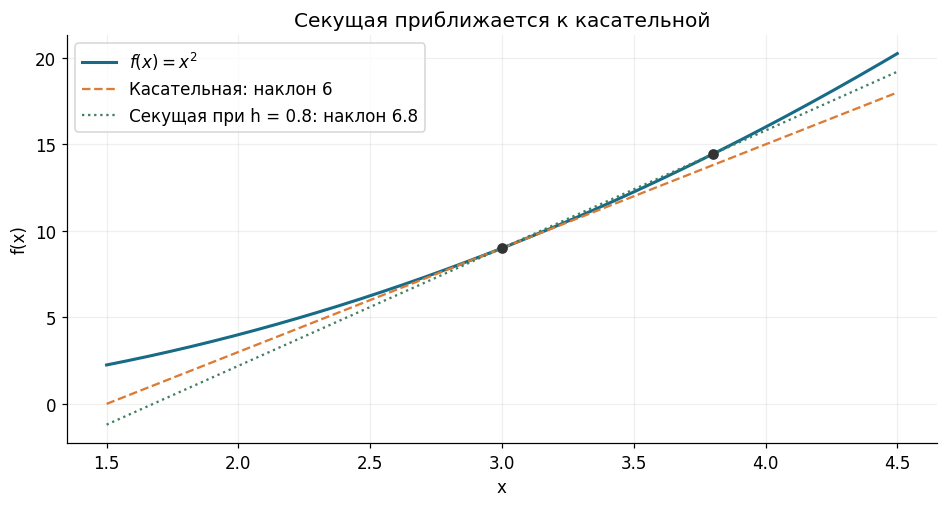

In [10]:
def square(value):
    return value ** 2

point_x = 3.0
print('h             Разностное отношение     Ошибка относительно 6')
for step_h in [1.0, 0.1, 0.01, 1e-4, 1e-8, 1e-12]:
    difference = (square(point_x + step_h) - square(point_x)) / step_h
    print(f'{step_h:<13.1e} {difference:<24.10f} {abs(difference - 6):.3e}')

grid_x = np.linspace(1.5, 4.5, 300)
secant_h = 0.8
secant_slope = (square(point_x + secant_h) - square(point_x)) / secant_h

fig, ax = plt.subplots()
ax.plot(grid_x, square(grid_x), label=r'$f(x)=x^2$', linewidth=2)
ax.plot(grid_x, 9 + 6 * (grid_x - 3), '--', label='Касательная: наклон 6')
ax.plot(grid_x, 9 + secant_slope * (grid_x - 3), ':',
        label=f'Секущая при h = {secant_h}: наклон {secant_slope:.1f}')
ax.scatter([3, 3 + secant_h], [9, square(3 + secant_h)], color='#333333', zorder=3)
ax.set(xlabel='x', ylabel='f(x)', title='Секущая приближается к касательной')
ax.legend()
plt.show()

**Разбор функции и численного расчёта.**

- `def square(value):` **определяет функцию** с именем `square` и одним параметром `value`. Параметр — локальное имя для переданного при вызове значения. Двоеточие начинает тело функции; его строки имеют отступ. Само определение ещё не вычисляет квадрат конкретного числа.
- `return value ** 2` возвращает результат вызывающему коду. `**` в Python означает возведение в степень: `3 ** 2` равно 9. В математической подписи квадрат часто пишется как $x^2$, но символ `^` в Python степень не вычисляет.
- `square(point_x + step_h)` — вызов созданной функции. Сначала считается аргумент, затем он передаётся под именем `value`. `return` возвращает число, которое далее участвует в вычитании и делении. `print` показывает текст, а `return` передаёт значение программе; это разные действия.
- `point_x = 3.0` задаёт точку. Цикл `for step_h in [...]` последовательно подставляет каждый шаг из списка; `difference` на каждой итерации получает заново посчитанное отношение.
- Запись числа `1e-4` означает $1\cdot10^{-4}=0{,}0001$; `1e-8` и `1e-12` — ещё меньшие числа. Буква `e` в **числовой записи Python** обозначает степень десяти и не является константой $e$ из экспоненты. Отрицательная степень означает обратную величину: $10^{-4}=1/10^4$.
- В `(...) / step_h` скобки объединяют разность числителя перед делением. `abs(difference - 6)` вычисляет модуль ошибки, убирая её знак.
- В форматах `{step_h:<13.1e}` и `{difference:<24.10f}` знак `<` означает выравнивание текста влево, числа 13 и 24 — минимальную ширину столбца. `.1e` — научная запись с одной цифрой после точки; `.10f` — обычная запись с десятью. `.3e` у ошибки задаёт три цифры после точки. Эти символы внутри строки управляют оформлением таблицы, а не меняют вычисления.

**Разбор рисунка.**

- `np.linspace(1.5, 4.5, 300)` создаёт массив из 300 равномерно расположенных точек от 1,5 до 4,5, включая границы. Он нужен для гладкого изображения линии. `square(grid_x)` получает сразу весь массив: NumPy возводит в квадрат каждый элемент.
- `secant_h` хранит один выбранный шаг 0,8; `secant_slope` — наклон секущей при этом шаге. Это отдельные переменные, не зависящие от последнего значения цикла `step_h`.
- `plt.subplots()` возвращает рисунок `fig` и область `ax`. Каждый `ax.plot(x, y, ...)` добавляет линию по массивам горизонтальных и вертикальных координат. `linewidth=2` задаёт толщину линии, `'--'` — штриховую линию, `':'` — точечную.
- В выражениях `9 + 6 * (grid_x - 3)` и `9 + secant_slope * (grid_x - 3)` сначала вычисляются отклонения входов от 3, затем соответствующие значения прямых. Это формулы линий, а не настройки рисунка.
- `ax.scatter([...], [...], ...)` добавляет две отдельные точки. `zorder=3` помещает их выше элементов с меньшим порядком рисования, чтобы они были видны поверх линий. `color` задаёт цвет.
- Префикс `r` и знаки `$...$` в подписи включают математическое оформление текста. `ax.set(...)` задаёт подписи и заголовок; `ax.legend()` собирает подписи `label`; `plt.show()` показывает рисунок.

При шаге $10^{-12}$ ошибка снова заметно растёт. Это наблюдаемый в выводе эффект ограниченной точности чисел, а не изменение формулы производной.

Уменьшение $h$ улучшает математическое приближение, но вычисления с плавающей точкой имеют ограниченную точность. При очень малом $h$ вычитаются почти одинаковые числа, и ошибка округления становится заметной. Поэтому численная производная не обязана становиться точнее при каждом уменьшении шага.

### 2.2. Правила дифференцирования и сложная функция

Базовые производные:

| Функция | Производная | Условие |
|---|---|---|
| $c$ | $0$ | $c$ — константа |
| $x^n$ | $nx^{n-1}$ | целое $n\ge1$ |
| $e^x$ | $e^x$ | $x\in\mathbb{R}$ |
| $\ln x$ | $1/x$ | $x>0$ |
| $\sqrt{x}$ | $1/(2\sqrt{x})$ | $x>0$ |

Для дифференцируемых функций:

$$[af(x)+bg(x)]'=af'(x)+bg'(x),$$
$$[f(x)g(x)]'=f'(x)g(x)+f(x)g'(x).$$

Если функция составлена из вложенных действий, применяется **правило цепочки**:

$$[f(g(x))]'=f'(g(x))\,g'(x).$$

Например, $F(x)=(2x+1)^2$. Внешняя операция — квадрат, внутренняя — $2x+1$. Поэтому

$$F'(x)=2(2x+1)\cdot2=4(2x+1),\qquad F'(1)=12.$$

Множитель 2 от внутренней функции обязателен. Производная описывает изменение по исходному $x$, а не только по промежуточному значению $2x+1$.

**Чтение формул.** В таблице $c$ — постоянное число, $n$ — положительное целое число. Например, $(x^3)'=3x^2$. Постоянная не меняется при изменении $x$, поэтому её производная равна нулю. $e\approx2{,}71828$ — математическая константа; $e^x$ — экспонента, а $\ln x$ отвечает на вопрос, в какую степень нужно возвести $e$, чтобы получить $x$. Например, $\ln e=1$.

В правилах для $af+bg$ числа $a,b$ — постоянные множители. Штрих снаружи квадратных скобок требует продифференцировать всё выражение внутри. В правиле произведения получаются два слагаемых: сначала меняется первая функция при фиксированной второй, затем вторая при фиксированной первой.

В $f(g(x))$ сначала вычисляется $g(x)$, затем к результату применяется $f$. Для $g(x)=2x+1$ и $f(u)=u^2$ производные равны $g'(x)=2$ и $f'(u)=2u$. Поэтому $F'(x)=2(2x+1)\cdot2$. При $x=1$ внутренняя скобка равна 3, и производная равна $2\cdot3\cdot2=12$.

Упомянутый порядок ошибки описывает, как убывает ошибка приближения при уменьшении шага: член порядка $h$ обычно уменьшается примерно вдвое при делении $h$ на 2, член порядка $h^2$ — примерно вчетверо. Это асимптотическое поведение для подходящей гладкой функции, а не обещание при любом $h$ и любой точности чисел.

Этот блок записывает составную функцию и сравнивает её производную по готовой формуле с оценкой по значениям слева и справа от точки. Оба вычисления относятся к одному входу 1; вывод позволяет проверить численный результат правила цепочки.

In [11]:
def composed_function(value):
    return (2 * value + 1) ** 2

chain_point = 1.0
small_step = 1e-5
analytic_derivative = 4 * (2 * chain_point + 1)
numeric_derivative = (
    composed_function(chain_point + small_step)
    - composed_function(chain_point - small_step)
) / (2 * small_step)

print('Производная по формуле:', analytic_derivative)
print(f'Центральная разность: {numeric_derivative:.6f}')

Производная по формуле: 12.0
Центральная разность: 12.000000


**Разбор кода.**

- `def composed_function(value):` создаёт функцию одного аргумента. Строка с отступом `return (2 * value + 1) ** 2` сначала умножает вход на 2, прибавляет 1 и возводит всю скобку в квадрат. Результат возвращается в место вызова.
- `chain_point = 1.0` задаёт точку, `small_step = 1e-5` — шаг $0{,}00001$. Переменная `analytic_derivative` получает значение явной формулы `4 * (2 * chain_point + 1)`; её имя означает «аналитическая производная».
- В выражении для `numeric_derivative` функция вызывается два раза: при `chain_point + small_step` и при `chain_point - small_step`. Затем из первого значения вычитается второе, а разность делится на `2 * small_step`.
- Большие круглые скобки вокруг многострочного числителя одновременно группируют арифметику и разрешают перенос строки без завершения инструкции. После закрытия скобки `/` продолжает это же выражение.
- `print` выводит два результата. В последней строке `f` включает подстановку `{numeric_derivative:.6f}`: число показывается с шестью цифрами после точки. Такой вывод скрывает возможное отличие в более далёких разрядах.

В обоих вариантах получается около 12. Это сопоставление конкретных расчётов, а не определение производной через округлённый вывод.

Здесь использована **центральная разность** $[F(x+h)-F(x-h)]/(2h)$. Она оценивает наклон по значениям с двух сторон точки. Для достаточно гладкой функции ошибка её приближения имеет порядок $h^2$, а у прямой разности — $h$; ошибки округления при этом сохраняются. Для квадратного многочлена центральная разность совпадает с точной производной в точной арифметике.

### 2.3. Частные производные и градиент

У функции нескольких переменных можно менять одну координату, фиксируя остальные. Так определяется **частная производная**. Для

$$q(x,y)=x^2+2y^2$$

получаем $\partial q/\partial x=2x$ и $\partial q/\partial y=4y$.

**Градиент** собирает все частные производные в вектор:

$$\nabla q(x,y)=\begin{bmatrix}2x\\4y\end{bmatrix}.$$

В точке $(2,1)$ значение функции равно 6, а градиент равен $(4,4)^\top$. Для малого векторного изменения:

$$q(\mathbf{x}+\Delta\mathbf{x})\approx q(\mathbf{x})+\nabla q(\mathbf{x})^\top\Delta\mathbf{x}.$$

Скалярное произведение из линейной алгебры теперь оценивает изменение функции. Среди направлений единичной евклидовой длины ненулевой градиент указывает направление самого быстрого локального роста, а противоположный вектор — убывания.

Шаг $\mathbf{x}_{\text{new}}=\mathbf{x}-\eta\nabla q(\mathbf{x})$ иллюстрирует это свойство. При $\eta=0{,}1$ из $(2,1)$ получается $(1{,}6;0{,}6)$ и $q=3{,}28$. Линейное приближение даёт $2{,}8$: различие возникает из-за кривизны. Слишком большой шаг может увеличить функцию — локальное направление не гарантирует уменьшения на любом расстоянии.

**Чтение формул и расчёт.** В центральной разности точки $x+h$ и $x-h$ находятся по разные стороны от $x$, а расстояние между ними равно $2h$: поэтому в знаменателе стоит именно $2h$.

У функции $q(x,y)$ два независимых входа. Знак $\partial$ в $\partial q/\partial x$ означает производную по одному из них при фиксированном другом. При изменении $x$ выражение $2y^2$ ведёт себя как константа и даёт производную 0; остаётся $2x$. При изменении $y$ множитель 2 сохраняется: производная $2y^2$ равна $2\cdot2y=4y$.

Знак $\nabla$ («набла») означает вектор частных производных в порядке координат. В точке $(2,1)$ получаем $(2\cdot2,4\cdot1)^\top=(4,4)^\top$. В формуле изменения $\nabla q^\top\Delta\mathbf{x}=4\Delta x+4\Delta y$ — одно число, оценка изменения $q$.

Греческая $\eta$ («эта») — положительный размер шага. Индекс «new» означает новую точку. При $\eta=0{,}1$ изменение равно $-0{,}1(4,4)^\top=(-0{,}4,-0{,}4)^\top$; новая точка $(1{,}6;0{,}6)$. Её значение $1{,}6^2+2\cdot0{,}6^2=2{,}56+0{,}72=3{,}28$. Линейная оценка равна $6+4(-0{,}4)+4(-0{,}4)=2{,}8$. При $\eta=1$ новая точка $(-2,-3)$ и значение $4+18=22$ — больше исходного 6.

Здесь двумя функциями Python описываются значение квадратичной функции и её градиент. Код сравнивает малый и большой шаг из одной начальной точки, а на карте линий уровня показывает только малый шаг; подписи линий — значения функции в соответствующих точках плоскости.

Начальная точка: [2. 1.] ; q = 6.0
Градиент: [4. 4.]
η = 0.1: точка [1.6 0.6]; q = 3.28; линейное приближение = 2.80
η = 1.0: точка [-2. -3.]; q = 22.00; линейное приближение = -26.00


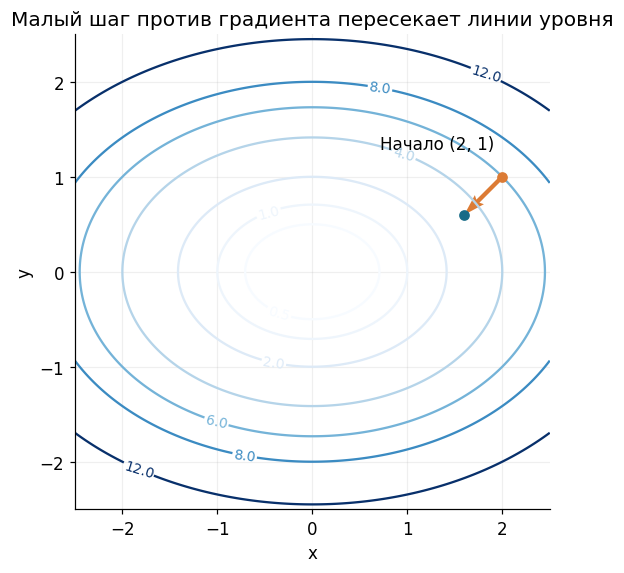

In [12]:
def quadratic(point):
    x_value, y_value = point
    return x_value ** 2 + 2 * y_value ** 2

def quadratic_gradient(point):
    x_value, y_value = point
    return np.array([2 * x_value, 4 * y_value])

start_point = np.array([2.0, 1.0])
gradient = quadratic_gradient(start_point)
print('Начальная точка:', start_point, '; q =', quadratic(start_point))
print('Градиент:', gradient)
for learning_step in [0.1, 1.0]:
    change = -learning_step * gradient
    new_point = start_point + change
    linear_prediction = quadratic(start_point) + gradient @ change
    print(f'η = {learning_step}: точка {new_point}; '
          f'q = {quadratic(new_point):.2f}; '
          f'линейное приближение = {linear_prediction:.2f}')

axis_values = np.linspace(-2.5, 2.5, 180)
mesh_x, mesh_y = np.meshgrid(axis_values, axis_values)
fig, ax = plt.subplots(figsize=(7.2, 5.1))
contours = ax.contour(mesh_x, mesh_y, mesh_x ** 2 + 2 * mesh_y ** 2,
                      levels=[0.5, 1, 2, 4, 6, 8, 12], cmap='Blues')
ax.clabel(contours, inline=True, fontsize=9)
small_change = -0.1 * gradient
ax.scatter(*start_point, color='#DC7B34', zorder=3)
ax.quiver(*start_point, *small_change, angles='xy', scale_units='xy',
          scale=1, color='#DC7B34', width=0.009)
ax.scatter(*(start_point + small_change), color='#176B87', zorder=3)
ax.annotate('Начало (2, 1)', start_point, xytext=(-80, 18),
            textcoords='offset points')
ax.set(xlabel='x', ylabel='y', title='Малый шаг против градиента пересекает линии уровня')
ax.set_aspect('equal')
plt.show()

**Разбор вычислений.**

- `def quadratic(point):` и `def quadratic_gradient(point):` определяют две разные функции. В обеих строка `x_value, y_value = point` распаковывает две координаты входного массива в два локальных имени. Порядок координат сохраняется; вход должен содержать ровно два элемента.
- Первая функция возвращает число `x_value ** 2 + 2 * y_value ** 2`, вторая — массив из двух частных производных `np.array([2 * x_value, 4 * y_value])`. `return` завершает выполнение соответствующей функции и передаёт результат.
- `start_point` хранит исходную точку. Вызов `quadratic_gradient(start_point)` вычисляет градиент один раз. `print` может принимать несколько аргументов: текст, массив и вычисленное число будут выведены в одной строке с пробелами.
- Цикл `for learning_step in [0.1, 1.0]:` рассматривает два размера шага. `-learning_step * gradient` меняет направление градиента и масштабирует его. `new_point = start_point + change` всегда начинает от той же `start_point`, а не продолжает движение из результата предыдущей итерации.
- В `linear_prediction` скалярное произведение `gradient @ change` оценивает изменение функции, которое прибавляется к исходному значению. В форматируемом выводе `{new_point}` показывает массив, а `.2f` ограничивает число знаков после точки у чисел. Несколько соседних `f`-строк внутри `print(...)` соединяются в одну подпись.

**Разбор карты уровней.**

- `np.linspace(...)` создаёт значения каждой оси. `np.meshgrid(axis_values, axis_values)` возвращает две двумерные таблицы: горизонтальную и вертикальную координату каждой точки сетки. Они распаковываются в `mesh_x`, `mesh_y`.
- `mesh_x ** 2 + 2 * mesh_y ** 2` поэлементно вычисляет значение функции во всех точках. `ax.contour(...)` строит линии одинакового значения. Список `levels=[...]` задаёт конкретные уровни, `cmap='Blues'` — набор оттенков.
- Результат построения сохраняется в `contours`. `ax.clabel(contours, inline=True, fontsize=9)` подписывает линии: `inline=True` оставляет место под число прямо на линии, `fontsize=9` задаёт размер текста.
- `small_change = -0.1 * gradient` отдельно фиксирует малый шаг для рисунка. `ax.scatter(*start_point, ...)` распаковывает две координаты точки в два аргумента. `ax.quiver(*start_point, *small_change, ...)` передаёт начальные координаты и два компонента стрелки. Звёздочка здесь распаковывает, а не умножает.
- В `ax.scatter(*(start_point + small_change), ...)` сначала складываются массивы, затем распаковываются координаты суммы. Параметры `color`, `zorder`, `width` задают цвет, порядок рисования и толщину; `angles`, `scale_units`, `scale` сохраняют масштаб стрелки в координатах осей.
- `ax.annotate(текст, start_point, ...)` добавляет пояснение к точке. `xytext=(-80, 18)` с `textcoords='offset points'` смещает текст на −80 и 18 типографских пунктов относительно точки; это смещение надписи на экране, не изменение данных.
- `ax.set(...)` задаёт подписи, `ax.set_aspect('equal')` сохраняет одинаковый масштаб координат, `plt.show()` выводит рисунок.

В таблице малый шаг уменьшает значение с 6 до 3,28, большой увеличивает его до 22. На карте виден переход от уровня 6 к меньшему значению, а не вся последовательность какого-либо алгоритма.

`plt.subplots(figsize=(7.2, 5.1))` создаёт рисунок и одну область осей; присваивание `fig, ax = ...` сохраняет эти два результата отдельно. Следующие методы с началом `ax.` относятся именно к этой области.

### 2.4. Вторая производная и экстремумы

Первая производная описывает скорость изменения функции. **Вторая производная** $f''(x)$ показывает, как меняется эта скорость, и характеризует кривизну.

Если дифференцируемая функция имеет локальный минимум во внутренней точке области определения, её производная там равна нулю. Обратное неверно: равенство $f'(x)=0$ само по себе минимума не гарантирует.

Для дважды непрерывно дифференцируемой функции в стационарной точке $x_0$, где $f'(x_0)=0$:

- $f''(x_0)>0$ — строгий локальный минимум;
- $f''(x_0)<0$ — строгий локальный максимум;
- $f''(x_0)=0$ — этот признак не даёт ответа.

У $f(x)=(x-2)^2+1$ производная $2(x-2)$ обращается в ноль при $x=2$, а вторая производная равна 2: это минимум со значением 1. У $g(x)=x^3$ в точке 0 обе производные равны нулю, но экстремума нет: функция продолжает возрастать.

**Чтение формул и расчёт.** Два штриха в $f''(x)$ означают производную от первой производной. Нижний индекс в $x_0$ — метка рассматриваемой точки. «Внутренняя» означает, что к точке можно подойти и слева, и справа, оставаясь в области определения.

Для $(x-2)^2+1$ первая производная $2(x-2)$ равна нулю при $x-2=0$, то есть при $x=2$. Производная выражения $2x-4$ равна 2, поэтому вторая производная положительна. Подстановка в исходную функцию даёт $(2-2)^2+1=1$.

Для $g(x)=x^3$ имеем $g'(x)=3x^2$, $g''(x)=6x$. При $x=0$ обе равны нулю. Однако $g(-0{,}1)=-0{,}001$, $g(0)=0$, $g(0{,}1)=0{,}001$: рядом есть и меньшие, и большие значения, поэтому ноль не является ни минимумом, ни максимумом.

Следующий блок строит рядом два графика с горизонтальной касательной в отмеченной точке. Левый показывает настоящий минимум, правый — возрастающую кубическую функцию без экстремума в нуле. Рядом их удобнее сравнить по значениям слева и справа от точки.

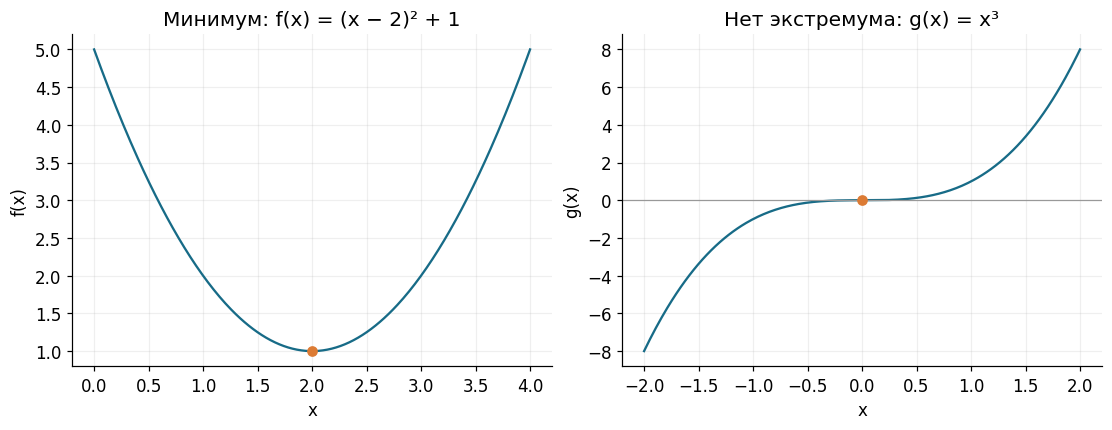

In [13]:
plot_x = np.linspace(-2.0, 2.0, 300)
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))
axes[0].plot(plot_x + 2, plot_x ** 2 + 1)
axes[0].scatter([2], [1], color='#DC7B34', zorder=3)
axes[0].set(title='Минимум: f(x) = (x − 2)² + 1', xlabel='x', ylabel='f(x)')
axes[1].plot(plot_x, plot_x ** 3)
axes[1].scatter([0], [0], color='#DC7B34', zorder=3)
axes[1].axhline(0, color='#999999', linewidth=0.8)
axes[1].set(title='Нет экстремума: g(x) = x³', xlabel='x', ylabel='g(x)')
plt.show()

**Разбор кода.**

- `plot_x = np.linspace(-2.0, 2.0, 300)` создаёт 300 значений от −2 до 2. Одно и то же имя используется для подготовки обоих графиков.
- `plt.subplots(1, 2, figsize=(10.0, 3.8))` создаёт **одну строку и два столбца** областей рисования. Первые два аргумента переданы по позиции: 1 — число строк, 2 — число столбцов. Результат распаковывается в `fig` и `axes`; здесь `axes` содержит два объекта осей.
- `axes[0]` выбирает левую область, `axes[1]` — правую: индексы начинаются с нуля. Последующее `.plot`, `.scatter` или `.set` вызывается именно у выбранной области.
- `axes[0].plot(plot_x + 2, plot_x ** 2 + 1)` сдвигает горизонтальные координаты на 2. Поэтому по первой оси фактически рисуется функция $(x-2)^2+1$ на интервале от 0 до 4. `axes[1].plot(plot_x, plot_x ** 3)` возводит каждое значение сетки в куб.
- `scatter([2], [1], ...)` и `scatter([0], [0], ...)` получают списки из одной координаты на каждой оси: это по одной выделенной точке. `color` задаёт цвет, `zorder=3` оставляет точки поверх кривых.
- `axhline(0, ...)` рисует горизонтальную линию на высоте 0; `linewidth=0.8` задаёт её толщину. Параметры `title`, `xlabel`, `ylabel` у `.set(...)` — тексты заголовка и подписей осей. Знаки `²` и `³` внутри строк — только удобное изображение степеней.
- Один вызов `plt.show()` выводит рисунок с обеими областями сразу.

У левой отмеченной точки все ближайшие значения выше. У правой есть и меньшие, и большие — отсутствие наклона в одной точке ещё не определяет экстремум.

### 2.5. Интеграл как накопление

**Определённый интеграл** складывает вклады функции на интервале:

$$\int_a^b f(x)\,dx.$$

Если $f(x)\ge0$, это площадь под графиком. Если функция меняет знак, интеграл учитывает участки ниже оси со знаком минус и не равен общей геометрической площади. Например, $\int_{-1}^1x\,dx=0$, хотя площадь двух треугольников ненулевая.

Если $F'(x)=f(x)$, то для непрерывной $f$ действует формула Ньютона — Лейбница:

$$\int_a^b f(x)\,dx=F(b)-F(a).$$

Для $f(x)=x^2$ первообразная $F(x)=x^3/3$, поэтому

$$\int_0^2x^2\,dx=\frac{2^3}{3}-0=\frac83\approx2{,}6667.$$

Когда известны значения функции на сетке, интеграл можно приближённо вычислить **методом трапеций**:

$$\int_a^b f(x)\,dx\approx\sum_{i=0}^{m-1}\frac{f(x_i)+f(x_{i+1})}{2}(x_{i+1}-x_i).$$

Каждое слагаемое — площадь трапеции с двумя соседними высотами. Для этой гладкой функции более мелкая сетка даёт более точный результат. Число узлов на единицу больше числа интервалов.

**Чтение формул и расчёт.** Знак $\int$ означает суммирование непрерывно распределённых вкладов. Нижняя граница $a$ — начало интервала, верхняя $b$ — конец. Запись $dx$ указывает переменную интегрирования; здесь это часть обозначения интеграла, а не произведение двух обычных чисел $d$ и $x$.

Буква $F$ обозначает первообразную: при её дифференцировании получается $f$. В $F(b)-F(a)$ сначала нужно подставить верхнюю границу, затем вычесть значение при нижней. Поэтому для $x^2$ на $[0,2]$ получается $2^3/3-0^3/3=8/3$. Квадратные скобки $[0,2]$ в тексте означают интервал со включёнными концами.

В методе трапеций $m$ — число маленьких интервалов; узлы нумеруются $x_0,x_1,\ldots,x_m$. В одном слагаемом $(f(x_i)+f(x_{i+1}))/2$ — средняя высота, $x_{i+1}-x_i$ — ширина. Их произведение даёт площадь трапеции. Сумма по $i=0,\ldots,m-1$ складывает все $m$ площадей. Для 10 равных интервалов ширина равна $(2-0)/10=0{,}2$, а узлов нужно 11.

В примере с $\int_{-1}^{1}x\,dx$ отрицательная площадь слева от нуля равна $-0{,}5$, положительная справа — $0{,}5$. Сумма равна нулю, тогда как сумма геометрических площадей равна 1.

Этот блок приближённо вычисляет один интеграл на трёх сетках и сравнивает ответы с точным значением. Каждое слагаемое собирается явно из высот и ширины трапеции; на отдельном рисунке закрашивается область, площадь которой вычисляется.

Интервалов:   10; интеграл: 2.68000000; ошибка: 1.33e-02
Интервалов:  100; интеграл: 2.66680000; ошибка: 1.33e-04
Интервалов: 1000; интеграл: 2.66666800; ошибка: 1.33e-06


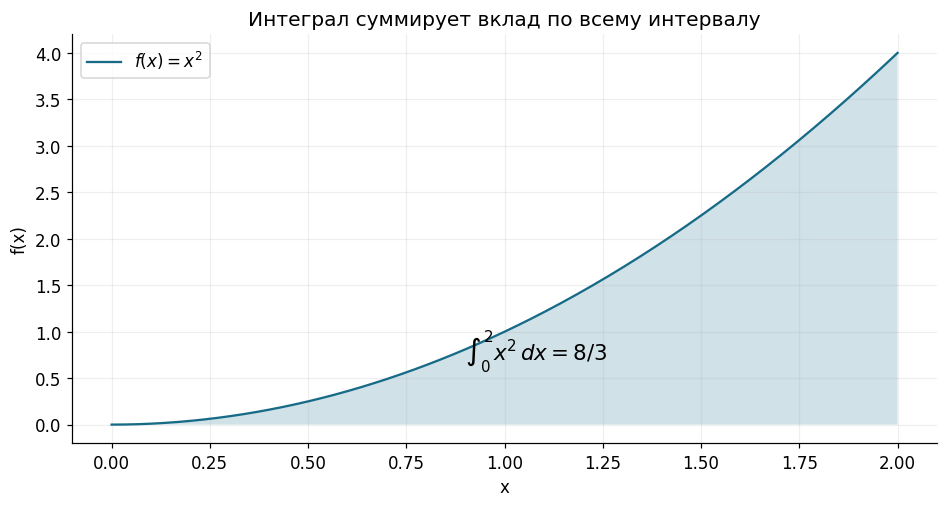

In [14]:
exact_integral = 8 / 3
for intervals in [10, 100, 1000]:
    integration_grid = np.linspace(0.0, 2.0, intervals + 1)
    heights = integration_grid ** 2
    trapezoid_areas = (heights[:-1] + heights[1:]) / 2 * np.diff(integration_grid)
    approximation = np.sum(trapezoid_areas)
    print(f'Интервалов: {intervals:4d}; интеграл: {approximation:.8f}; '
          f'ошибка: {abs(approximation - exact_integral):.2e}')

area_grid = np.linspace(0.0, 2.0, 300)
fig, ax = plt.subplots()
ax.plot(area_grid, area_grid ** 2, label=r'$f(x)=x^2$')
ax.fill_between(area_grid, area_grid ** 2, alpha=0.2)
ax.text(0.9, 0.7, r'$\int_0^2 x^2\,dx=8/3$', fontsize=14)
ax.set(xlabel='x', ylabel='f(x)', title='Интеграл суммирует вклад по всему интервалу')
ax.legend()
plt.show()

**Разбор численного расчёта.**

- `exact_integral = 8 / 3` сохраняет дробный результат деления. В Python оператор `/` даёт обычное деление с дробным результатом и тогда, когда оба исходных числа целые.
- Цикл `for intervals in [10, 100, 1000]:` выполняет один и тот же расчёт при трёх числах интервалов. Все строки с отступом относятся к очередной сетке.
- `np.linspace(0.0, 2.0, intervals + 1)` получает количество **узлов**, поэтому к числу интервалов прибавляется 1. `heights = integration_grid ** 2` вычисляет все высоты одной поэлементной операцией.
- `heights[:-1]` — срез от начала до последнего элемента **без последнего**. Отрицательный индекс `-1` означает последний элемент, но правая граница среза не включается. `heights[1:]` — срез со второго элемента до конца. Получаются массивы левых и правых высот одинаковой длины.
- `np.diff(integration_grid)` вычисляет разности соседних узлов, то есть ширины интервалов. Выражение `(heights[:-1] + heights[1:]) / 2` даёт средние высоты, а `*` поэлементно умножает их на ширины. `np.sum(trapezoid_areas)` складывает площади всех трапеций.
- В форматируемой строке `{intervals:4d}` выводит целое число в поле минимальной ширины 4; буква `d` обозначает десятичное целое. `.8f` показывает восемь знаков после точки, `.2e` — научную запись ошибки с двумя. `abs(...)` превращает отклонение от точного ответа в его неотрицательный размер.

**Разбор рисунка.** После цикла отступ заканчивается, поэтому рисунок строится один раз. `area_grid` создаёт отдельную сетку только для изображения. `ax.plot(...)` рисует кривую, `ax.fill_between(area_grid, area_grid ** 2, alpha=0.2)` закрашивает область между кривой и нулевой линией; `alpha` задаёт прозрачность.

`ax.text(0.9, 0.7, r'...')` размещает формулу в заданных координатах. Префикс `r` сохраняет обратные косые черты, `$...$` включает математическое оформление; `\int`, `\,` относятся к рисунку формулы и не вычисляют интеграл в Python. `.set(...)`, `.legend()` и `plt.show()` оформляют и показывают результат.

Ошибки порядка $10^{-2}$, $10^{-4}$ и $10^{-6}$ в выводе относятся к трём разным сеткам. Их можно читать как дроби со знаменателями — степенями десяти.

`print(...)` внутри цикла выводит одну строку для текущего количества интервалов. После завершения цикла `plt.subplots()` создаёт отдельный рисунок и область `ax` для единственного графика площади.

<a id="probability"></a>
## 3. Теория вероятностей

### 3.1. Случайный опыт, события и правила вероятности

**Случайный опыт** имеет заранее неизвестный исход. Множество всех возможных исходов обозначают $\Omega$. **Событие** — подмножество $\Omega$. Для одного броска кубика $\Omega=\{1,2,3,4,5,6\}$, а событие «выпало чётное» — $A=\{2,4,6\}$.

Вероятность удовлетворяет условиям $0\le P(A)\le1$ и $P(\Omega)=1$. Если конечные исходы **равновероятны**, то

$$P(A)=\frac{\text{число исходов в }A}{\text{число исходов в }\Omega}.$$

Именно предположение о равновероятности позволяет считать исходы. Для нечестного кубика одной мощности множеств недостаточно.

Обозначения: $A\cap B$ — произошли оба события; $A\cup B$ — произошло хотя бы одно; $\overline A$ — событие $A$ не произошло. Основные правила:

$$P(\overline A)=1-P(A),$$
$$P(A\cup B)=P(A)+P(B)-P(A\cap B).$$

Вычитание пересечения устраняет двойной учёт. Пусть $A$ — чётное число, $B$ — число больше 4. Тогда $A\cap B=\{6\}$, а $A\cup B=\{2,4,5,6\}$, поэтому $P(A\cup B)=3/6+2/6-1/6=4/6$.

**Чтение формул и расчёт.** Греческая $\Omega$ («омега») — множество всех исходов. Фигурные скобки $\{1,2,3,4,5,6\}$ перечисляют его элементы. В математике множество не учитывает порядок и повторения элементов. $P(A)$ читается «вероятность события $A$» и выражается числом от 0 до 1; $0{,}5$ — то же, что 50%.

Черта над $A$ означает дополнение, поэтому для чётного результата $P(\overline A)=1-3/6=3/6$. Знак $\cap$ означает пересечение, $\cup$ — объединение. В примере $A\cap B$ содержит один исход 6, значит его вероятность $1/6$; объединение содержит четыре исхода, значит $4/6$. В правиле сложения один и тот же исход 6 попал в обе отдельные вероятности, поэтому один раз вычитается.

Следующий блок представляет исходы кубика и два события как множества Python. Код находит их пересечение и объединение, считает доли исходов и сравнивает прямой подсчёт вероятности объединения с правилом сложения.

In [15]:
outcomes = set(range(1, 7))
event_a = {2, 4, 6}
event_b = {5, 6}

prob_a = len(event_a) / len(outcomes)
prob_b = len(event_b) / len(outcomes)
prob_intersection = len(event_a & event_b) / len(outcomes)
prob_union = len(event_a | event_b) / len(outcomes)

print('Пересечение:', sorted(event_a & event_b))
print('Объединение:', sorted(event_a | event_b))
print(f'P(A) = {prob_a:.3f}; P(B) = {prob_b:.3f}')
print(f'P(A ∩ B) = {prob_intersection:.3f}')
print(f'P(A ∪ B) напрямую: {prob_union:.3f}')
print(f'По правилу сложения: {prob_a + prob_b - prob_intersection:.3f}')

Пересечение: [6]
Объединение: [2, 4, 5, 6]
P(A) = 0.500; P(B) = 0.333
P(A ∩ B) = 0.167
P(A ∪ B) напрямую: 0.667
По правилу сложения: 0.667


**Разбор кода.**

- `range(1, 7)` задаёт последовательность целых от 1 **до 7, не включая 7**: 1, 2, 3, 4, 5, 6. `set(...)` превращает её во множество; в `outcomes` сохраняются все шесть исходов.
- `{2, 4, 6}` и `{5, 6}` — записи множеств через фигурные скобки. В отличие от словаря настроек в первой ячейке, здесь перечислены отдельные элементы без пар `ключ: значение`. Множество не хранит повторения и не задаёт математически значимого порядка.
- `len(объект)` — встроенная функция количества элементов. Поэтому `len(event_a) / len(outcomes)` делит число подходящих исходов на общее число равновероятных исходов. Результат `/` — дробное число.
- Для множеств `event_a & event_b` означает пересечение, `event_a | event_b` — объединение. Эти знаки действуют на сами множества; символы `∩` и `∪` в строках вывода служат только подписями.
- `sorted(...)` создаёт упорядоченный список элементов, чтобы перечисление исходов было удобно читать. Само исходное множество при этом не меняется. Число элементов `len(...)` не зависит от сортировки.
- `prob_a`, `prob_b`, `prob_intersection`, `prob_union` — имена четырёх вычисленных вероятностей. В последнем `print` выражение `prob_a + prob_b - prob_intersection` заново собирает правило сложения из чисел.
- Префикс `f` подставляет значения внутрь текста; формат `.3f` выводит три цифры после точки. Например, `0.667` — округлённая запись $4/6$, а не точная конечная десятичная дробь для этой вероятности.

Одинаковый вывод двух последних строк показывает совпадение прямого подсчёта и формулы в данном примере.

### 3.2. Условная вероятность, независимость и формула Байеса

**Условная вероятность** учитывает уже известное событие. Если $P(B)>0$, то

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$

Мы ограничиваем множество возможных исходов событием $B$ и заново нормируем вероятности. В примере с кубиком среди чисел больше 4 только одно чётное, поэтому $P(A\mid B)=1/2$.

События **независимы**, если $P(A\cap B)=P(A)P(B)$. При $P(B)>0$ это равносильно $P(A\mid B)=P(A)$. В данном примере события независимы, хотя описаны через один бросок: $1/6=(1/2)(1/3)$.

Независимость отличается от несовместности. Несовместные события не могут произойти одновременно. Если оба имеют положительную вероятность, они зависимы: наступление одного исключает другое.

**Формула полной вероятности** складывает вклады непересекающихся случаев $H_1,\ldots,H_k$, покрывающих все исходы:

$$P(S)=\sum_{i=1}^k P(S\mid H_i)P(H_i).$$

**Формула Байеса** меняет направление условной вероятности:

$$P(H_i\mid S)=\frac{P(S\mid H_i)P(H_i)}{P(S)},\qquad P(S)>0.$$

Разбор на условных данных проверки деталей. Пусть $D$ — дефект, $S$ — сигнал системы. Задано:

- $P(D)=0{,}02$: дефект есть у 2% деталей;
- $P(S\mid D)=0{,}90$: система подаёт сигнал для 90% дефектных;
- $P(S\mid\overline D)=0{,}10$: система подаёт сигнал для 10% исправных.

Тогда $P(S)=0{,}90\cdot0{,}02+0{,}10\cdot0{,}98=0{,}116$, а

$$P(D\mid S)=\frac{0{,}90\cdot0{,}02}{0{,}116}\approx0{,}1552.$$

Среди деталей с сигналом ожидается около **15,5% дефектных**, хотя для дефектной детали вероятность сигнала равна 90%. Это разные условия. Низкая исходная доля дефектов приводит к большому числу сигналов от исправных деталей. Все числа здесь учебные и не описывают реальную систему.

**Чтение формул и расчёт.** Вертикальная черта в $P(A\mid B)$ читается «при условии $B$». В числителе остаются исходы, удовлетворяющие обоим условиям; деление на $P(B)$ пересчитывает их долю среди исходов $B$. Для кубика $(1/6)/(2/6)=1/2$. Условие $P(B)>0$ необходимо, чтобы не делить на ноль.

В формуле полной вероятности $H_i$ — один из отдельных случаев, $i$ — его номер, $k$ — число случаев. Вклад каждого случая равен произведению вероятности этого случая и вероятности сигнала внутри него. В примере случаев два: есть дефект $D$ и нет дефекта $\overline D$.

В формуле Байеса числитель $P(S\mid D)P(D)=0{,}9\cdot0{,}02=0{,}018$ — вероятность одновременно дефекта и сигнала. Вклад исправных равен $0{,}1\cdot0{,}98=0{,}098$. Общая вероятность сигнала $0{,}018+0{,}098=0{,}116$ служит знаменателем. Деление $0{,}018/0{,}116\approx0{,}1552$ переводит долю от всех деталей в долю внутри группы с сигналом.

Проверка через ожидаемые количества даёт ту же дробь: в партии из 10 000 деталей ожидается 200 дефектных, из них сигнал у 180; исправных 9800, из них сигнал у 980. Получаем $180/(180+980)\approx0{,}1552$. Для независимости знак произведения в $P(A)P(B)$ означает обычное умножение двух чисел; он не означает, что события несовместны.

Здесь численно разбирается сигнал проверки деталей: сначала рассчитываются общая вероятность сигнала и вероятность дефекта при сигнале, затем ожидаемые количества для партии. Горизонтальная полоса разделяется на две части, показывая состав именно группы с сигналом.

P(сигнал) = 0.116
P(дефект | сигнал) = 15.52%
В партии из 10000 деталей ожидаются:
  сигналы от дефектных: 180
  сигналы от исправных: 980


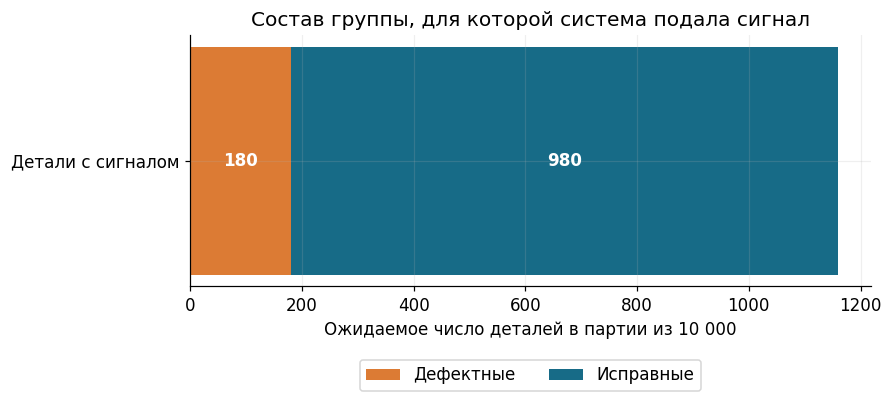

In [16]:
defect_probability = 0.02
signal_given_defect = 0.90
signal_given_good = 0.10

signal_probability = (
    signal_given_defect * defect_probability
    + signal_given_good * (1 - defect_probability)
)
defect_given_signal = signal_given_defect * defect_probability / signal_probability

batch_size = 10_000
expected_defect_signals = batch_size * defect_probability * signal_given_defect
expected_good_signals = batch_size * (1 - defect_probability) * signal_given_good

print(f'P(сигнал) = {signal_probability:.3f}')
print(f'P(дефект | сигнал) = {defect_given_signal:.2%}')
print(f'В партии из {batch_size} деталей ожидаются:')
print(f'  сигналы от дефектных: {expected_defect_signals:.0f}')
print(f'  сигналы от исправных: {expected_good_signals:.0f}')

fig, ax = plt.subplots(figsize=(8.0, 3.5))
ax.barh(['Детали с сигналом'], [expected_defect_signals],
        label='Дефектные', color='#DC7B34')
ax.barh(['Детали с сигналом'], [expected_good_signals],
        left=[expected_defect_signals], label='Исправные', color='#176B87')
ax.text(expected_defect_signals / 2, 0, f'{expected_defect_signals:.0f}',
        ha='center', va='center', color='white', fontweight='bold')
ax.text(expected_defect_signals + expected_good_signals / 2, 0,
        f'{expected_good_signals:.0f}', ha='center', va='center',
        color='white', fontweight='bold')
ax.set(xlabel='Ожидаемое число деталей в партии из 10 000',
       title='Состав группы, для которой система подала сигнал')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.26), ncol=2)
plt.show()

**Разбор расчётов и вывода.**

- Три первые переменные хранят исходные вероятности как дроби: `0.02` соответствует 2%, `0.90` — 90%, `0.10` — 10%. Имена с подчёркиваниями описывают смысл числа, но не являются специальными словами Python.
- В `signal_probability` круглыми скобками объединена сумма двух произведений. Выражение `1 - defect_probability` находит долю исправных. В следующем присваивании умножение и деление дают формулу Байеса; результат сохраняется в отдельную переменную.
- `batch_size = 10_000` задаёт целое 10000. Подчёркивание **внутри числовой записи** отделяет разряды для читателя и не меняет значение. `batch_size * вероятность` переводит долю в ожидаемое число деталей.
- Префикс `f` включает подстановки в строки. Формат `.2%` сам умножает дробь на 100, добавляет знак процента и оставляет две цифры после точки. `.3f` выводит обычную дробь с тремя знаками, `.0f` — число без знаков после точки. Пробелы в начале строки `'  сигналы...'` нужны только для оформления вывода.

**Разбор полосы.**

- `plt.subplots(figsize=(8.0, 3.5))` создаёт рисунок заданного размера и область `ax`. `ax.barh(...)` рисует горизонтальный столбец: первый аргумент — список названий категорий, второй — список длин. В каждом списке здесь один элемент.
- Второй `barh` получает `left=[expected_defect_signals]`: исправные детали рисуются **после** части дефектных. Списки нужны потому, что метод рассчитан и на несколько столбцов. `label` задаёт подпись части для легенды, `color` — цвет.
- `ax.text(x, y, текст, ...)` размещает число. Деление длины первой части на 2 даёт её центр, сумма `expected_defect_signals + expected_good_signals / 2` — центр второй части. Координата `y=0` соответствует первой категории.
- Параметры `ha='center'`, `va='center'` выравнивают текст горизонтально и вертикально по центру. `color='white'` делает текст белым, `fontweight='bold'` — полужирным.
- `ax.set(...)` задаёт подпись и заголовок. В `.legend(...)` параметр `loc='upper center'` выбирает точку привязки легенды, `bbox_to_anchor=(0.5, -0.26)` размещает её под графиком в относительных координатах области, `ncol=2` располагает подписи в двух столбцах. `plt.show()` выводит рисунок.

Количество 180 относится к дефектным с сигналом, 980 — к исправным с сигналом. Делить 180 нужно на сумму этих двух частей 1160, что и даёт около 15,52%.

Каждый `print(...)` выводит очередную строку текста или чисел. Отступы пробелами внутри строк видны в результате, а отступы продолжения инструкции внутри круглых скобок служат только для удобства чтения исходного кода.

### 3.3. Случайная величина и дискретное распределение

**Случайная величина** сопоставляет исходам числа. Например, $X=1$, если событие произошло, и $X=0$ иначе. **Распределение** задаёт вероятности возможных значений. Для дискретной величины сумма вероятностей всех значений равна 1.

**Распределение Бернулли** описывает один опыт с двумя результатами:

$$P(X=1)=p,\qquad P(X=0)=1-p.$$

**Биномиальное распределение** описывает число успехов $K$ в $n$ независимых опытах с одной и той же вероятностью успеха $p$:

$$P(K=k)=\binom nk p^k(1-p)^{n-k},\qquad k=0,\ldots,n.$$

Здесь $\binom nk=n!/[k!(n-k)!]$ — число способов выбрать позиции $k$ успехов, $n!=1\cdot2\cdots n$, $0!=1$. Для одного выбранного порядка вероятность равна $p^k(1-p)^{n-k}$; биномиальный коэффициент учитывает все порядки.

При $n=10$, $p=0{,}3$ вероятность **ровно трёх** успехов равна

$$P(K=3)=\binom{10}{3}\,0{,}3^3\,0{,}7^7\approx0{,}2668.$$

Это не вероятность «не более трёх»: для неё нужно сложить вероятности $k=0,1,2,3$. При зависимости испытаний или разных значениях $p$ обычная биномиальная формула в общем случае неприменима.

**Чтение формул и расчёт.** Запись $P(X=1)$ обозначает вероятность события «случайная величина $X$ приняла значение 1». Буква $p$ — число от 0 до 1. Для Бернулли возможны только значения 0 и 1; их вероятности $1-p$ и $p$ в сумме дают 1.

В биномиальной формуле $n$ — общее число опытов, $k$ — конкретное число успехов. Границы $k=0,\ldots,n$ включают оба конца: от отсутствия успехов до успеха во всех опытах. Степень $p^k$ умножает вероятность успеха саму на себя $k$ раз, $(1-p)^{n-k}$ учитывает оставшиеся неуспехи. При нулевом числе соответствующих множителей их произведение принимается равным 1.

Знак «!» — факториал, а не восклицание. Для $n=10$, $k=3$ получаем $\binom{10}{3}=10!/(3!7!)=(10\cdot9\cdot8)/(3\cdot2\cdot1)=120$. Значит, вероятность трёх успехов — $120\cdot0{,}3^3\cdot0{,}7^7\approx0{,}2668$. Вероятность «не более трёх» записывается $P(K\le3)$ и равна сумме четырёх отдельных вероятностей, а не одному слагаемому.

Следующий блок вычисляет вероятности всех возможных чисел успехов в десяти испытаниях. Из полученного массива отдельно берутся вероятность ровно трёх успехов и сумма для значений от нуля до трёх; столбчатый график показывает всё распределение.

Сумма вероятностей: 1.000000
P(K = 3) = 0.266828
P(K ≤ 3) = 0.649611


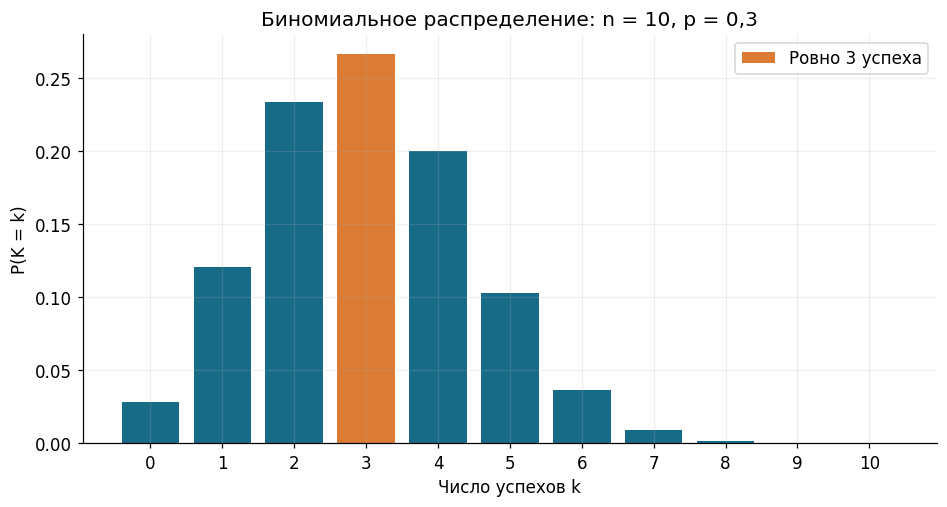

In [17]:
trials = 10
success_probability = 0.3
success_counts = np.arange(trials + 1)
binomial_probabilities = np.array([
    comb(trials, int(count))
    * success_probability ** count
    * (1 - success_probability) ** (trials - count)
    for count in success_counts
])

print(f'Сумма вероятностей: {binomial_probabilities.sum():.6f}')
print(f'P(K = 3) = {binomial_probabilities[3]:.6f}')
print(f'P(K ≤ 3) = {binomial_probabilities[:4].sum():.6f}')

fig, ax = plt.subplots()
ax.bar(success_counts, binomial_probabilities, color='#176B87')
ax.bar([3], [binomial_probabilities[3]], color='#DC7B34', label='Ровно 3 успеха')
ax.set(xticks=success_counts, xlabel='Число успехов k', ylabel='P(K = k)',
       title='Биномиальное распределение: n = 10, p = 0,3')
ax.legend()
plt.show()

**Разбор вычислений.**

- `trials = 10` задаёт число испытаний, `success_probability = 0.3` — вероятность успеха. `np.arange(trials + 1)` создаёт массив целых от 0 до 10: правая граница 11 не включается. При одном аргументе начало `arange` по умолчанию равно 0, шаг — 1.
- Запись `[выражение for count in success_counts]` называется **списковым включением**. Она проходит по всем значениям `success_counts`, подставляет очередное в `count`, вычисляет выражение перед `for` и собирает результаты в новый список. Это краткая запись последовательного заполнения списка.
- `comb(trials, int(count))` вычисляет число сочетаний. Функция `comb` подключена в первой ячейке. `int(count)` переводит целочисленный элемент NumPy в обычное целое Python, подходящее для аргумента этой функции.
- Операторы `**` возводят вероятность успеха и неуспеха в нужные степени. `trials - count` — число неуспехов. Произведения `*` объединяют коэффициент и две степени в вероятность одного значения.
- Внешний вызов `np.array([...])` превращает собранный список вероятностей в массив, с которым удобно считать суммы и строить график.
- `binomial_probabilities.sum()` — метод суммы массива; результат тот же, что у `np.sum(binomial_probabilities)`. Запись `.sum()` вызывает метод без дополнительных аргументов.
- Индекс `[3]` выбирает вероятность для значения 3, потому что массив начинается с вероятности нуля успехов. Срез `[:4]` берёт элементы с индексами 0, 1, 2, 3, не включая индекс 4; последующее `.sum()` складывает эти четыре вероятности.
- В форматируемом выводе `.6f` показывает шесть цифр после точки. Символы `=` и `≤` внутри текста — подписи соответствующих событий, а не инструкции сравнения Python.

**Разбор рисунка.** `ax.bar(success_counts, binomial_probabilities, ...)` рисует вертикальные столбцы: первый массив задаёт горизонтальные позиции, второй — высоты. Дополнительный `bar([3], [...], ...)` накладывает выделенный столбец в позиции 3. `color` задаёт цвет, `label` — подпись в легенде. В `ax.set(...)` параметр `xticks=success_counts` отмечает на оси все целые значения; остальные параметры задают тексты. `.legend()` и `plt.show()` завершают вывод.

Сумма вероятностей равна 1. Вероятность «не более трёх» больше вероятности «ровно три», потому что включает ещё три возможных значения.

`print(...)` показывает три численных итога: сумму всего распределения и две интересующие вероятности. `plt.subplots()` затем создаёт рисунок и одну область `ax`, на которой размещаются столбцы.

### 3.4. Математическое ожидание, дисперсия и стандартное отклонение

**Математическое ожидание** — среднее значение с весами-вероятностями. Для дискретной величины с возможными значениями $x_i$ и вероятностями $p_i$:

$$\mu=\mathbb{E}[X]=\sum_i x_i p_i.$$

Это характеристика распределения, а не обязательно возможный результат одного опыта. У кубика ожидание равно 3,5, хотя такого числа на гранях нет.

**Дисперсия** измеряет средний квадрат отклонения от ожидания, а **стандартное отклонение** — корень из дисперсии:

$$\operatorname{Var}(X)=\mathbb{E}[(X-\mu)^2]=\sum_i(x_i-\mu)^2p_i,\qquad
\sigma=\sqrt{\operatorname{Var}(X)}.$$

Дисперсия неотрицательна. Если $X$ измеряется в секундах, дисперсия измеряется в квадратных секундах, а стандартное отклонение — снова в секундах. Полезные свойства:

$$\mathbb{E}[aX+b]=a\mathbb{E}[X]+b,\qquad
\operatorname{Var}(aX+b)=a^2\operatorname{Var}(X).$$

Добавление константы сдвигает среднее, но не меняет разброс. Линейность ожидания суммы не требует независимости.

Для $X\sim\operatorname{Bernoulli}(p)$ ожидание равно $p$, дисперсия — $p(1-p)$. Для $K\sim\operatorname{Binomial}(n,p)$ получаем $\mathbb{E}[K]=np$, $\operatorname{Var}(K)=np(1-p)$: независимые испытания позволяют складывать дисперсии.

Разберём другое распределение: значения $0,1,2$ имеют вероятности $0{,}2;0{,}5;0{,}3$. Тогда $\mu=1{,}1$, а дисперсия равна $0{,}2\cdot1{,}1^2+0{,}5\cdot0{,}1^2+0{,}3\cdot0{,}9^2=0{,}49$.

**Чтение формул и расчёт.** Символ $\mathbb{E}[X]$ обозначает математическое ожидание. Греческая $\mu$ («мю») — краткое имя того же числа. В сумме $\sum_i x_ip_i$ каждый возможный результат $x_i$ получает вес $p_i$. Для примера: $0\cdot0{,}2+1\cdot0{,}5+2\cdot0{,}3=1{,}1$.

Обозначение $\operatorname{Var}(X)$ — дисперсия, а $\sigma$ («сигма») — стандартное отклонение. Квадрат в $(x_i-\mu)^2$ делает вклад неотрицательным и сильнее учитывает большие отклонения. Здесь отклонения равны $-1{,}1;-0{,}1;0{,}9$, квадраты — $1{,}21;0{,}01;0{,}81$. После умножения на вероятности сумма равна $0{,}242+0{,}005+0{,}243=0{,}49$, корень — $0{,}7$.

В свойствах $aX+b$ числа $a,b$ постоянны. Умножение на $a$ изменяет отклонения в $a$ раз, а их квадраты — в $a^2$ раз. Прибавление $b$ одинаково сдвигает все значения и среднее, поэтому отклонения сохраняются. Знак $\sim$ в $K\sim\operatorname{Binomial}(n,p)$ читается «имеет распределение». Произведение $np$ означает $n\cdot p$: при $n=10$, $p=0{,}3$ ожидание равно 3, дисперсия $10\cdot0{,}3\cdot0{,}7=2{,}1$.

Здесь ожидание и дисперсия сначала вычисляются по небольшому явно заданному распределению. Затем те же действия применяются к уже полученному биномиальному распределению, и результаты сравниваются с короткими формулами через число испытаний и вероятность успеха.

In [18]:
possible_values = np.array([0.0, 1.0, 2.0])
probabilities = np.array([0.2, 0.5, 0.3])

expectation = possible_values @ probabilities
variance = ((possible_values - expectation) ** 2) @ probabilities
standard_deviation = np.sqrt(variance)

print(f'Математическое ожидание: {expectation:.2f}')
print(f'Дисперсия: {variance:.2f}')
print(f'Стандартное отклонение: {standard_deviation:.2f}')

binomial_mean_from_sum = success_counts @ binomial_probabilities
binomial_variance_from_sum = (
    (success_counts - binomial_mean_from_sum) ** 2
) @ binomial_probabilities
print(f'Биномиальное распределение: E[K] = {binomial_mean_from_sum:.2f}; '
      f'Var(K) = {binomial_variance_from_sum:.2f}')
print(f'Те же значения по формулам: np = {trials * success_probability:.2f}; '
      f'np(1 − p) = {trials * success_probability * (1 - success_probability):.2f}')

Математическое ожидание: 1.10
Дисперсия: 0.49
Стандартное отклонение: 0.70
Биномиальное распределение: E[K] = 3.00; Var(K) = 2.10
Те же значения по формулам: np = 3.00; np(1 − p) = 2.10


**Разбор кода.**

- `possible_values` содержит возможные значения, `probabilities` — соответствующие им вероятности в том же порядке. Первые элементы относятся друг к другу, вторые — друг к другу и так далее; длины массивов совпадают.
- `possible_values @ probabilities` умножает пары элементов и складывает произведения, поэтому сразу даёт взвешенное среднее. Это применение ранее введённого скалярного произведения, а не обычного среднего по трём значениям.
- В `((possible_values - expectation) ** 2) @ probabilities` число `expectation` вычитается из каждого элемента, каждый результат возводится в квадрат оператором `**`, затем `@` выполняет взвешенное суммирование. Скобки группируют этапы расчёта.
- `np.sqrt(variance)` — функция квадратного корня NumPy. Результат сохраняется под именем `standard_deviation`; переменная `variance` продолжает хранить дисперсию.
- `success_counts` и `binomial_probabilities` взяты из предыдущей ячейки. Поэтому расчёт `binomial_mean_from_sum` использует те же пары «значение — вероятность», но уже для 11 возможных чисел успехов.
- Многострочная запись `binomial_variance_from_sum` — одно выражение: сначала квадраты отклонений внутри круглых скобок, затем скалярное произведение с вероятностями после закрывающей скобки.
- В фигурных скобках `f`-строк вычисляются как отдельные переменные, так и произведения `trials * success_probability` и `trials * success_probability * (1 - success_probability)`. `.2f` оформляет результаты с двумя знаками после точки. Соседние строковые части внутри `print(...)` соединяются.
- Подпись `np` **внутри текста** последнего `print` означает математическое произведение $n\cdot p$. Она не обращается к библиотеке `np`: реальные вычисления записаны отдельно внутри `{...}`.

Первое распределение даёт ожидание 1,1, дисперсию 0,49 и стандартное отклонение 0,7. Для биномиального случая оба способа дают ожидание 3 и дисперсию 2,1.

`np.array(...)` в двух первых строках создаёт массивы значений и вероятностей из списков. Скобки вызова окружают список целиком, запятые внутри списка разделяют его элементы.

### 3.5. Непрерывная величина, плотность и нормальное распределение

Для **абсолютно непрерывной** случайной величины распределение задаётся плотностью $f_X(x)$:

$$f_X(x)\ge0,\qquad\int_{-\infty}^{+\infty}f_X(x)\,dx=1.$$

Вероятность интервала — интеграл плотности:

$$P(a\le X\le b)=\int_a^b f_X(x)\,dx.$$

Значение плотности в точке **не равно вероятности точки**. Для величины с плотностью $P(X=x)=0$ при любом отдельном $x$. Плотность может быть больше 1: у равномерного распределения на $[0;0{,}5]$ высота равна 2, а площадь — 1. Если $x$ измеряется в секундах, плотность имеет единицы $1/\text{секунда}$.

Функция распределения $F_X(t)=P(X\le t)$ накапливает вероятность слева от $t$. Для величины с плотностью $P(a\le X\le b)=F_X(b)-F_X(a)$. Ожидание и дисперсия при их существовании также вычисляются интегралами:

$$\mu=\int_{-\infty}^{+\infty}x f_X(x)\,dx,\qquad
\operatorname{Var}(X)=\int_{-\infty}^{+\infty}(x-\mu)^2f_X(x)\,dx.$$

**Нормальное распределение** $X\sim\mathcal{N}(\mu,\sigma^2)$ имеет плотность

$$f_X(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\qquad \sigma>0.$$

Параметр $\mu$ — ожидание, $\sigma^2$ — дисперсия. Стандартизованная величина $Z=(X-\mu)/\sigma$ имеет распределение $\mathcal{N}(0,1)$.

Пусть время обработки условно моделируется как $\mathcal{N}(10,2^2)$ секунд. Тогда интервал от 8 до 12 секунд соответствует $\mu\pm\sigma$ и содержит примерно **68,27%** вероятности. Это свойство именно нормального распределения. Его выбор — предположение модели, а не следствие того, что известны среднее и дисперсия. В частности, нормальное распределение допускает отрицательные значения; для времени такая модель может быть лишь приближением.

**Чтение формул и расчёт.** Индекс $X$ в $f_X(x)$ указывает, плотность какой случайной величины рассматривается. Аргумент $x$ — конкретное значение на горизонтальной оси. У интеграла от $-\infty$ до $+\infty$ берётся вся числовая прямая; $\infty$ обозначает неограниченное продолжение, а не число для подстановки.

В $F_X(t)=P(X\le t)$ буква $t$ задаёт порог. Разность $F_X(b)-F_X(a)$ вычитает из всей вероятности слева от $b$ ту часть, которая уже накопилась слева от $a$. Для распределения с плотностью отдельные концы интервала не меняют вероятность. В интегралах ожидания и дисперсии множитель $f_X(x)$ играет роль непрерывного аналога весов $p_i$.

В $\mathcal{N}(\mu,\sigma^2)$ второй параметр — именно дисперсия; при стандартном отклонении 2 это $2^2=4$. Константа $\pi\approx3{,}14159$ — число пи, $\exp(u)=e^u$. Чтобы посчитать плотность, из $x$ вычитается $\mu$, результат возводится в квадрат, делится на $2\sigma^2$ и берётся со знаком минус. Затем вычисляется экспонента и умножается на $1/(\sigma\sqrt{2\pi})$.

В самой середине, $x=\mu=10$, показатель равен 0, экспонента — 1, и плотность равна $1/(2\sqrt{2\pi})\approx0{,}1995$. При $x=8$ или $12$ стандартизованное значение $z=(x-10)/2$ равно соответственно $-1$ или 1. Интервал $\mu\pm\sigma$ означает две границы $\mu-\sigma$ и $\mu+\sigma$, а не одно значение.

Следующий блок создаёт описание нормального распределения, считает вероятность интервала через накопленные вероятности и отдельно выводит высоту плотности в центре. Затем плотность вычисляется на сетке для рисунка, а нужный интервал выделяется заливкой.

P(8 ≤ X ≤ 12) = 68.2689%
Плотность в точке 10: 0.1995 1/с
Вероятность ровно одного значения в этой модели равна 0.


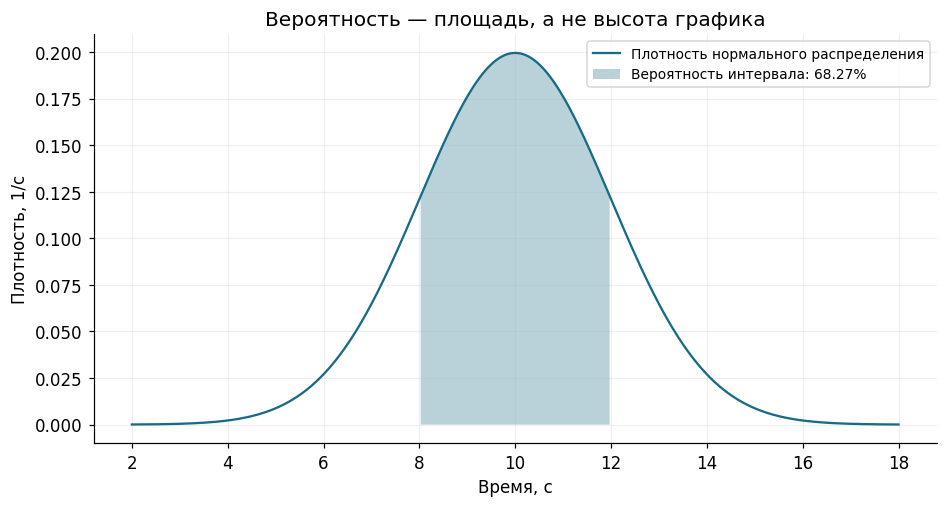

In [19]:
normal_mean = 10.0
normal_std = 2.0
normal_distribution = NormalDist(mu=normal_mean, sigma=normal_std)
lower_bound, upper_bound = 8.0, 12.0
interval_probability = (
    normal_distribution.cdf(upper_bound)
    - normal_distribution.cdf(lower_bound)
)
print(f'P(8 ≤ X ≤ 12) = {interval_probability:.4%}')
print(f'Плотность в точке 10: {normal_distribution.pdf(10):.4f} 1/с')
print('Вероятность ровно одного значения в этой модели равна 0.')

normal_grid = np.linspace(2.0, 18.0, 500)
normal_density = np.exp(-0.5 * ((normal_grid - normal_mean) / normal_std) ** 2)
normal_density /= normal_std * np.sqrt(2 * np.pi)

fig, ax = plt.subplots()
ax.plot(normal_grid, normal_density, label='Плотность нормального распределения')
ax.fill_between(normal_grid, normal_density,
                where=(normal_grid >= lower_bound) & (normal_grid <= upper_bound),
                alpha=0.3, label=f'Вероятность интервала: {interval_probability:.2%}')
ax.set(xlabel='Время, с', ylabel='Плотность, 1/с',
       title='Вероятность — площадь, а не высота графика')
ax.legend(loc='upper right', fontsize=9)
plt.show()

**Разбор распределения и чисел.**

- `normal_mean` и `normal_std` — два числа: ожидание и стандартное отклонение. `NormalDist(mu=normal_mean, sigma=normal_std)` создаёт объект, описывающий нормальное распределение с этими параметрами. `NormalDist` — имя подключённого **класса**, то есть вида объектов; его вызов создаёт конкретный экземпляр. Здесь `sigma` получает стандартное отклонение, а не дисперсию.
- `lower_bound, upper_bound = 8.0, 12.0` — присваивание двух значений двум именам по порядку: нижней и верхней границе. Запятые выполняют упаковку справа и распаковку слева.
- Метод `normal_distribution.cdf(граница)` возвращает вероятность не превысить границу. Разность двух таких вызовов сохраняется в `interval_probability`. Метод `.pdf(10)` возвращает плотность в точке 10; эти методы отвечают на разные вопросы.
- В формате `.4%` дробь переводится в проценты с четырьмя цифрами после точки. `.4f` у плотности выводит обычное число с четырьмя знаками. Последний `print` выводит готовое пояснение без числовой подстановки.

**Разбор вычисления плотности и заливки.**

- `np.linspace(2.0, 18.0, 500)` создаёт 500 значений для горизонтальной оси. Вычитание среднего и деление на стандартное отклонение применяются к каждому элементу массива.
- `np.exp(...)` вычисляет экспоненту $e^u$ для каждого переданного значения. Внутри вызова сначала рассчитывается квадрат стандартизованного отклонения, затем он умножается на `-0.5`.
- `normal_density /= normal_std * np.sqrt(2 * np.pi)` означает «разделить текущие значения `normal_density` на правую часть и сохранить результат обратно». Для этих чисел это соответствует записи `normal_density = normal_density / (...)`. Константа `np.pi` — число пи, `np.sqrt` — квадратный корень.
- Выражение `normal_grid >= lower_bound` поэлементно сравнивает значения с нижней границей и создаёт массив `True`/`False`. Аналогично `<=` проверяет верхнюю. Знак `&` между двумя такими массивами означает поэлементное «оба условия истинны». Скобки вокруг каждого сравнения нужны для правильного порядка операций.
- Параметр `where=...` в `ax.fill_between(...)` задаёт, где делать заливку: только в точках с `True`. Параметр `alpha=0.3` задаёт прозрачность, `label` содержит подпись с вычисленной вероятностью. `ax.plot(...)` строит саму кривую.
- `ax.set(...)` задаёт подписи осей и заголовок. В `ax.legend(loc='upper right', fontsize=9)` выбраны правый верхний угол и размер текста легенды. `plt.show()` показывает рисунок.

Число 0,1995 — высота графика в центре, а 68,2689% — площадь выделенного интервала. Их нельзя подменять друг другом.

`plt.subplots()` создаёт один рисунок и одну область: имена `fig` и `ax` слева принимают два результата вызова. Последующие методы `ax.plot(...)` и `ax.fill_between(...)` рисуют на одной и той же области.

### 3.6. Распределение и выборка: параметры и оценки

На практике распределение часто неизвестно, доступны только наблюдения $x_1,\ldots,x_n$ — **выборка**. Характеристики распределения $\mu,\sigma^2$ отличаются от их оценок по конечной выборке.

**Выборочное среднее**:

$$\overline x=\frac1n\sum_{i=1}^n x_i.$$

Средний квадрат отклонений в имеющихся данных:

$$v_n=\frac1n\sum_{i=1}^n(x_i-\overline x)^2.$$

Если выборка состоит из независимых одинаково распределённых наблюдений с конечной дисперсией, то **несмещённая оценка дисперсии распределения** при $n>1$ равна

$$s^2=\frac1{n-1}\sum_{i=1}^n(x_i-\overline x)^2.$$

Делитель $n-1$ учитывает оценивание среднего по тем же данным. Несмещённость означает $\mathbb{E}[s^2]=\sigma^2$ при многократном получении таких выборок, а не точное совпадение в одной выборке. Корень $s$ сам по себе не является в общем случае несмещённой оценкой $\sigma$.

В NumPy `np.var(..., ddof=0)` делит на $n$; `ddof=1` — на $n-1$. Оба вычисления могут быть уместны, но отвечают разным целям: описание конкретного набора данных или оценивание дисперсии распределения.

**Чтение формул и расчёт.** $n$ — число наблюдений, $x_i$ — наблюдение с номером $i$, черта в $\overline x$ обозначает выборочное среднее. Буквы $v_n$ и $s^2$ — два разных варианта вычисления дисперсии; верхнее 2 у $s^2$ соответствует квадрату выборочного стандартного отклонения $s$.

Для $1,2,3,4,5$ среднее равно $(1+2+3+4+5)/5=3$. Отклонения равны $-2,-1,0,1,2$, квадраты — $4,1,0,1,4$, их сумма — 10. Деление на $n=5$ даёт $v_n=2$, деление на $n-1=4$ даёт $s^2=2{,}5$. Корень $s=\sqrt{2{,}5}\approx1{,}5811$ выражен в единицах исходных данных.

В равенстве $\mathbb{E}[s^2]=\sigma^2$ ожидание берётся по возможным повторным выборкам: при смене наблюдений значение $s^2$ тоже меняется. Для одной выборки это не равенство её численной оценки неизвестному параметру. Ограничение $n>1$ нужно, чтобы знаменатель $n-1$ был положительным.

В этом блоке одна короткая выборка используется для вычисления среднего и двух вариантов дисперсии. Сначала отдельно находится сумма квадратов отклонений, затем библиотечные функции с разными делителями показывают, откуда берутся отличающиеся результаты.

In [20]:
sample = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
sample_mean = np.mean(sample)
squared_deviations = np.sum((sample - sample_mean) ** 2)

print('Наблюдения:', sample)
print(f'Выборочное среднее: {sample_mean:.2f}')
print(f'Сумма квадратов отклонений: {squared_deviations:.2f}')
print(f'Дисперсия с делителем n: {np.var(sample, ddof=0):.2f}')
print(f'Оценка с делителем n − 1: {np.var(sample, ddof=1):.2f}')
print(f'Стандартное отклонение с ddof=1: {np.std(sample, ddof=1):.4f}')

Наблюдения: [1. 2. 3. 4. 5.]
Выборочное среднее: 3.00
Сумма квадратов отклонений: 10.00
Дисперсия с делителем n: 2.00
Оценка с делителем n − 1: 2.50
Стандартное отклонение с ddof=1: 1.5811


**Разбор кода.**

- `sample = np.array([...])` создаёт массив пяти наблюдений. `np.mean(sample)` складывает его элементы и делит на их количество; результат присваивается `sample_mean`.
- В `np.sum((sample - sample_mean) ** 2)` вычитание числа из массива вычисляет все отклонения, `** 2` возводит каждое в квадрат, а `np.sum` складывает квадраты. Вложенные скобки отделяют вызов функции от арифметической группы.
- `np.var(sample, ddof=0)` вычисляет дисперсию с делителем `n - 0`. Параметр `ddof=1` меняет делитель на `n - 1`. Имя `ddof` — название настройки функции, а не переменная, которую нужно предварительно создать.
- `np.std(sample, ddof=1)` вычисляет корень из дисперсии с тем же делителем. Название `std` сокращает английское «стандартное отклонение»; `var` — «дисперсия», `mean` — «среднее».
- `print('Наблюдения:', sample)` выводит весь массив, а следующие `f`-строки подставляют рассчитанные числа или результаты вызовов функций. Форматы `.2f` и `.4f` оставляют соответственно два и четыре знака после точки.

Сумма квадратов равна 10. Один и тот же числитель при делении на 5 даёт 2, а при делении на 4 — 2,5; различие определяется параметром `ddof`.

### 3.7. Ковариация, корреляция и зависимость

Для двух величин важен не только отдельный разброс, но и совместное изменение. **Ковариация** определяется как

$$\operatorname{Cov}(X,Y)=\mathbb{E}[(X-\mu_X)(Y-\mu_Y)].$$

Когда обе величины обычно отклоняются от своих средних в одну сторону, ковариация положительна; в разные стороны — отрицательна. Её численное значение зависит от единиц измерения.

**Корреляция Пирсона** нормирует ковариацию:

$$\rho_{XY}=\frac{\operatorname{Cov}(X,Y)}{\sigma_X\sigma_Y},\qquad -1\le\rho_{XY}\le1.$$

Она определена только при ненулевых стандартных отклонениях. Значения $\pm1$ соответствуют точной линейной связи; значение 0 означает отсутствие линейной связи по этой характеристике, но не отсутствие любой зависимости.

Для пар наблюдений выборочная ковариация с делителем $n-1$ равна $\sum_i(x_i-\overline x)(y_i-\overline y)/(n-1)$. Матрица ковариаций объединяет дисперсии и ковариации:

$$\Sigma=\begin{bmatrix}
\operatorname{Var}(X)&\operatorname{Cov}(X,Y)\\
\operatorname{Cov}(X,Y)&\operatorname{Var}(Y)
\end{bmatrix}.$$

При независимости и конечных вторых моментах ковариация равна нулю. Обратное в общем случае неверно. Например, если $X$ равномерно распределена на $[-2,2]$, а $Y=X^2$, то из симметрии $\operatorname{Cov}(X,Y)=0$, хотя $Y$ полностью определяется по $X$.

На правом графике показана симметричная сетка, иллюстрирующая этот случай. Корреляция также не устанавливает причинность: даже сильная линейная связь сама по себе не объясняет, почему величины меняются вместе.

**Чтение формул и расчёт.** $\operatorname{Cov}(X,Y)$ — ковариация двух величин. Внутри ожидания стоят два отклонения от своих средних. У произведения положительный знак, когда оба отклонения одного знака, и отрицательный — когда знаки разные. В выборочной формуле суммируются произведения **пар с одним номером**: перестановка значений только одного столбца меняет пары и результат.

Для пар из кода среднее каждого столбца равно 3. Произведения отклонений равны $(-2)(-1),(-1)(-2),0\cdot1,1\cdot0,2\cdot2$, то есть $2,2,0,0,4$. Сумма 8, выборочная ковариация $8/(5-1)=2$. Дисперсия каждого столбца с тем же делителем равна $2{,}5$, поэтому корреляция $2/(\sqrt{2{,}5}\sqrt{2{,}5})=0{,}8$.

Греческая $\rho$ («ро») обозначает корреляцию распределения; буква $r$ на графике — корреляцию по данным. $\sigma_X,\sigma_Y$ — стандартные отклонения соответствующих величин. Заглавная $\Sigma$ — матрица ковариаций, она отличается от строчной $\sigma$ и от знака суммирования $\sum$. На её диагонали стоят дисперсии, вне диагонали — ковариации.

В примере $Y=X^2$ отклонения $X$ симметричны относительно нуля: вклады от $x$ и $-x$ в ковариацию взаимно уничтожаются. Это объясняет нулевую линейную корреляцию при сохраняющейся зависимости $Y$ от $X$.

Следующий блок рассчитывает ковариацию пар наблюдений вручную и с помощью NumPy, затем выводит корреляцию. На двух рисунках сравниваются эти пары и точки параболы, у которой почти нулевая корреляция не мешает точной зависимости одного значения от другого.

Выборочная ковариация: 2.00
Матрица выборочных ковариаций:
 [[2.5 2. ]
 [2.  2.5]]
Корреляция первой пары: 0.8000
Корреляция для y = x² на симметричной сетке: 0.000000


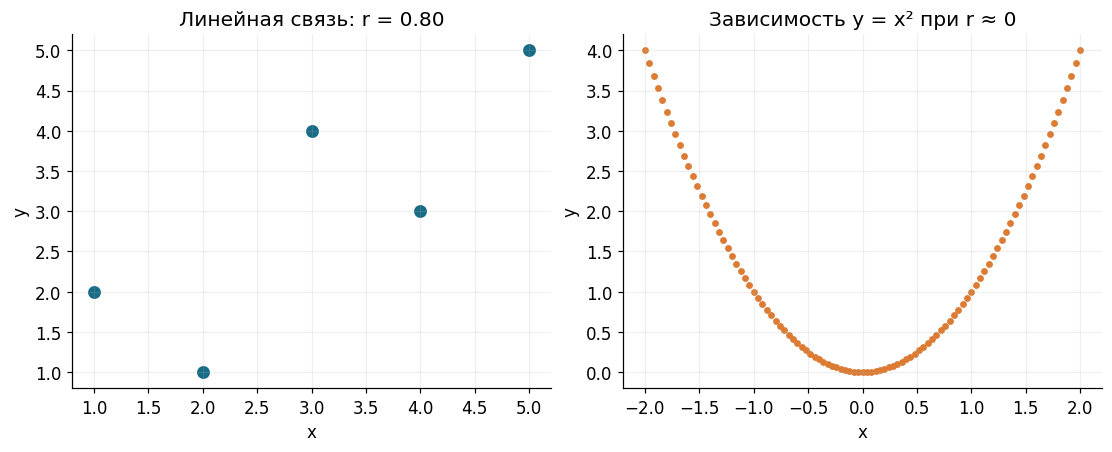

In [21]:
paired_x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
paired_y = np.array([2.0, 1.0, 4.0, 3.0, 5.0])
sample_covariance = (
    (paired_x - paired_x.mean()) @ (paired_y - paired_y.mean())
) / (paired_x.size - 1)
sample_correlation = np.corrcoef(paired_x, paired_y)[0, 1]

print(f'Выборочная ковариация: {sample_covariance:.2f}')
print('Матрица выборочных ковариаций:\n', np.cov(paired_x, paired_y, ddof=1))
print(f'Корреляция первой пары: {sample_correlation:.4f}')

nonlinear_x = np.linspace(-2.0, 2.0, 101)
nonlinear_y = nonlinear_x ** 2
nonlinear_correlation = np.corrcoef(nonlinear_x, nonlinear_y)[0, 1]
print(f'Корреляция для y = x² на симметричной сетке: {nonlinear_correlation:.6f}')

fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0))
axes[0].scatter(paired_x, paired_y, s=55)
axes[0].set(xlabel='x', ylabel='y', title=f'Линейная связь: r = {sample_correlation:.2f}')
axes[1].scatter(nonlinear_x, nonlinear_y, s=12, color='#DC7B34')
axes[1].set(xlabel='x', ylabel='y', title='Зависимость y = x² при r ≈ 0')
plt.show()

**Разбор вычислений.**

- `paired_x` и `paired_y` — массивы одинаковой длины. Элементы с одинаковыми индексами образуют пару: например, первые элементы 1 и 2 относятся к одному наблюдению.
- Метод `paired_x.mean()` вычисляет то же среднее, что `np.mean(paired_x)`. Вызовы `.mean()` у обоих массивов дают их отдельные средние. Их вычитание из исходных массивов создаёт два набора отклонений.
- Оператор `@` перемножает соответствующие отклонения и складывает произведения. Деление на `(paired_x.size - 1)` даёт ковариацию с делителем $n-1$. Атрибут `.size` — общее количество элементов массива, здесь 5; его чтение не требует круглых скобок.
- `np.corrcoef(paired_x, paired_y)` возвращает матрицу корреляций двух переменных. Последующее `[0, 1]` выбирает первую строку и второй столбец этой матрицы — корреляцию `x` с `y`. На диагонали стоят корреляции каждой переменной с собой.
- `np.cov(paired_x, paired_y, ddof=1)` возвращает матрицу ковариаций: диагональ содержит две дисперсии, другие элементы — ковариации. Настройка `ddof=1` явно задаёт делитель $n-1$. Последовательность `\n` в подписи переносит матрицу на следующую строку.
- `nonlinear_x = np.linspace(-2.0, 2.0, 101)` создаёт симметричную сетку, `nonlinear_y = nonlinear_x ** 2` поэлементно вычисляет квадрат. Корреляция для этих двух массивов извлекается тем же `[0, 1]`. Формат `.6f` может показать ноль, даже если из-за округления вычислено очень малое ненулевое число.

**Разбор рисунков.** `plt.subplots(1, 2, ...)` создаёт две области, `axes[0]` и `axes[1]` выбирают левую и правую. Метод `.scatter(x, y, s=...)` рисует отдельные точки; `s` задаёт их площадь в квадратных типографских пунктах. `color` меняет цвет. Методы `.set(...)` назначают подписи и заголовки; в первом заголовке `f`-строка подставляет корреляцию с форматом `.2f`. Один `plt.show()` выводит обе области.

Ковариация 2 и корреляция 0,8 относятся к первой паре столбцов. Почти нулевое число для параболы относится к другим данным и не означает, что координаты там независимы.

Первые два `np.array(...)` создают массивы из списков наблюдений. Вызовы `print(...)` выводят промежуточные характеристики и позволяют сравнить явную формулу ковариации с результатом библиотечной функции.

### 3.8. Повторные наблюдения и устойчивость среднего

Для независимых одинаково распределённых наблюдений с конечной дисперсией среднее становится устойчивее при увеличении объёма выборки. Закон больших чисел утверждает сходимость выборочного среднего к математическому ожиданию; он **не обещает монотонного уменьшения ошибки** на каждом шаге.

Разброс среднего по повторным выборкам характеризует **стандартная ошибка среднего**:

$$\operatorname{Var}(\overline X_n)=\frac{\sigma^2}{n},\qquad
\operatorname{SE}(\overline X_n)=\frac{\sigma}{\sqrt n}.$$

Это разброс средних разных выборок, а не разброс отдельных наблюдений. Если $\sigma$ неизвестна, её обычно оценивают по выборке. Зависимость между наблюдениями может нарушить приведённую формулу.

Для наблюдений Бернулли с $p=0{,}3$ среднее равно доле успехов, а теоретическая стандартная ошибка равна $\sqrt{0{,}3\cdot0{,}7/n}$. Чтобы уменьшить её вдвое, объём выборки нужно увеличить в четыре раза.

Ниже одна смоделированная последовательность. `default_rng` с фиксированным начальным значением делает пример воспроизводимым в используемой среде. Генератор создаёт псевдослучайные числа; фиксированное значение не улучшает точность оценки. Удлинение выборки может временно отдалять долю от $p$.

**Чтение формул и расчёт.** Заглавная $\overline X_n$ обозначает среднее как случайную величину: до получения выборки его значение неизвестно. Нижний индекс $n$ — объём выборки. Строчная $\overline x$ — уже посчитанное среднее конкретных наблюдений.

В $\operatorname{Var}(\overline X_n)=\sigma^2/n$ слева стоит дисперсия средних, справа — дисперсия одного наблюдения, делённая на число наблюдений. Обозначение $\operatorname{SE}$ — стандартная ошибка; корень из дисперсии даёт $\sigma/\sqrt n$. Например, при $p=0{,}3$ и $n=100$ это $\sqrt{0{,}21/100}\approx0{,}0458$.

При увеличении $n$ в четыре раза корень $\sqrt n$ увеличивается в два раза, поэтому стандартная ошибка уменьшается вдвое. Эта формула описывает масштаб случайных отклонений по повторным выборкам. Она не утверждает, что ошибка одной траектории в каждый момент точно равна указанному числу или непрерывно уменьшается.

В этом блоке моделируются пять тысяч опытов с результатами 0 или 1. После каждого опыта вычисляется накопленная доля единиц; для нескольких объёмов выводится сравнение с теоретическим масштабом разброса среднего. Два рисунка отдельно показывают одну случайную траекторию и теоретическую зависимость ошибки от объёма.

n       Доля успехов     Теоретическая стандартная ошибка
10      0.5000           0.1449
100     0.2700           0.0458
1000    0.3040           0.0145
5000    0.2944           0.0065


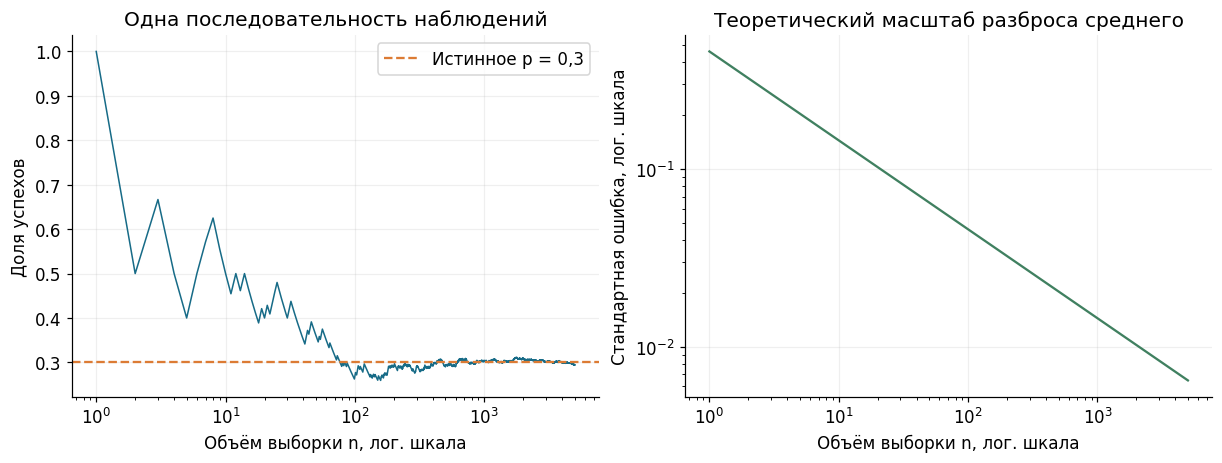

In [22]:
bernoulli_rng = np.random.default_rng(42)
observations = bernoulli_rng.binomial(n=1, p=0.3, size=5000)
observation_counts = np.arange(1, observations.size + 1)
running_fraction = np.cumsum(observations) / observation_counts
theoretical_se = np.sqrt(0.3 * 0.7 / observation_counts)

print('n       Доля успехов     Теоретическая стандартная ошибка')
for count in [10, 100, 1000, 5000]:
    print(f'{count:<7d} {running_fraction[count - 1]:<16.4f} '
          f'{theoretical_se[count - 1]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.1))
axes[0].plot(observation_counts, running_fraction, linewidth=1)
axes[0].axhline(0.3, linestyle='--', color='#DC7B34', label='Истинное p = 0,3')
axes[0].set(xscale='log', xlabel='Объём выборки n, лог. шкала',
            ylabel='Доля успехов', title='Одна последовательность наблюдений')
axes[0].legend()
axes[1].plot(observation_counts, theoretical_se, color='#408060')
axes[1].set(xscale='log', yscale='log', xlabel='Объём выборки n, лог. шкала',
            ylabel='Стандартная ошибка, лог. шкала',
            title='Теоретический масштаб разброса среднего')
plt.show()

**Разбор данных и расчётов.**

- `np.random` — часть NumPy для псевдослучайных чисел. `np.random.default_rng(42)` создаёт **генератор**, объект с собственным состоянием; число 42 задаёт его начальное состояние. Имя `bernoulli_rng` сохраняет генератор для последующих вызовов.
- Метод `.binomial(n=1, p=0.3, size=5000)` выдаёт 5000 независимых в модели значений биномиального распределения. При `n=1` каждое значение — 0 или 1. Аргумент `p` задаёт вероятность единицы, `size` — число выдаваемых значений; это не число испытаний внутри одного результата.
- `observations.size` возвращает длину массива. `np.arange(1, observations.size + 1)` создаёт числа от 1 до 5000 включительно: прибавление 1 нужно, потому что правая граница `arange` не включается.
- `np.cumsum(observations)` — **накопленная сумма**: каждый элемент хранит сумму от начала массива до текущего места. Деление на `observation_counts` поэлементно превращает эти суммы в доли. `np.sum` в отличие от `np.cumsum` вернул бы одну общую сумму.
- `np.sqrt(0.3 * 0.7 / observation_counts)` вычисляет теоретическую стандартную ошибку для каждого объёма; `np.sqrt` применяется ко всему массиву поэлементно.
- Цикл `for count in [10, 100, 1000, 5000]:` печатает только четыре выбранные строки. Для объёма `count` нужен элемент `[count - 1]`, потому что массив нумеруется с нуля: объёму 10 соответствует индекс 9.
- Формат `{count:<7d}` выравнивает целое влево в поле ширины 7. `{...:<16.4f}` выводит дробь с четырьмя знаками в поле ширины 16; `.4f` в последнем столбце тоже задаёт четыре знака. Соседние строковые части внутри `print(...)` объединяются.

**Разбор рисунков.** `plt.subplots(1, 2, ...)` создаёт две области. `.plot(...)` строит линии; `linewidth=1` задаёт толщину. Метод `.axhline(0.3, linestyle='--', ...)` рисует горизонтальную опорную линию, параметр `linestyle` выбирает штриховой стиль. `.legend()` выводит подпись этой линии.

Параметры `xscale='log'`, `yscale='log'` в `.set(...)` включают логарифмическую шкалу: равные расстояния на оси показывают одинаковые **отношения** значений, например рост от 10 до 100 и от 100 до 1000. На правом графике таких шкал две, на левом — только горизонтальная. Нулевые значения на логарифмическую ось не наносятся; размеры выборки и теоретические ошибки здесь положительны. `plt.show()` выводит весь рисунок.

Таблица и левый рисунок относятся к одной сгенерированной последовательности. Правый график зависит только от заданного $p$ и объёма, поэтому он гладкий, тогда как наблюдаемая доля колеблется.

<a id="connection"></a>
## 4. Один пример, объединяющий три раздела

Пусть есть два безразмерных случайных измерения $X_1$ и $X_2$. Рассчитывается взвешенная величина

$$Z=2X_1-X_2=\mathbf{w}^\top\mathbf{X},\qquad\mathbf{w}=(2,-1)^\top.$$

**Линейная алгебра** позволяет вычислить $Z$ сразу для всех строк матрицы наблюдений: `observations @ weights`.

**Математический анализ** описывает чувствительность по входам:

$$\nabla_{\mathbf{x}}z=\begin{bmatrix}2\\-1\end{bmatrix}.$$

Увеличение первого входа на $0{,}1$ при фиксированном втором увеличивает $z$ на $0{,}2$. Увеличение второго на $0{,}1$ уменьшает $z$ на $0{,}1$. Для этой линейной функции формула изменения через градиент точна при любом размере изменения.

**Теория вероятностей** описывает среднее и разброс результата. Для вектора ожиданий $\boldsymbol\mu$ и матрицы ковариаций $\Sigma$:

$$\mathbb{E}[Z]=\mathbf{w}^\top\boldsymbol\mu,\qquad
\operatorname{Var}(Z)=\mathbf{w}^\top\Sigma\mathbf{w}.$$

В двух измерениях вторая формула разворачивается как

$$\operatorname{Var}(w_1X_1+w_2X_2)=w_1^2\operatorname{Var}(X_1)+w_2^2\operatorname{Var}(X_2)
+2w_1w_2\operatorname{Cov}(X_1,X_2).$$

Пусть измерения независимы, их ожидания равны 3 и 4, а стандартные отклонения — $0{,}5$ и 1. Тогда

$$\boldsymbol\mu=\begin{bmatrix}3\\4\end{bmatrix},\quad
\Sigma=\begin{bmatrix}0{,}25&0\\0&1\end{bmatrix},\quad
\mathbb{E}[Z]=2,\quad\operatorname{Var}(Z)=2,\quad\sigma_Z=\sqrt2.$$

При зависимости измерений внедиагональные элементы $\Sigma$ в общем случае ненулевые, и их вклад нельзя отбрасывать. Формулы ожидания и дисперсии не требуют нормальности. Для следующего численного примера дополнительно выбраны независимые нормальные входы; при этом $Z$ также имеет нормальное распределение.

**Чтение формул и расчёт.** Вектор $\mathbf{X}=(X_1,X_2)^\top$ содержит две случайные величины, а $\mathbf{x}$ — пару уже полученных значений. Индекс в $\nabla_{\mathbf{x}}z$ уточняет, что производные берутся по входам: производная $2x_1-x_2$ по $x_1$ равна 2, по $x_2$ — $-1$.

Вектор $\boldsymbol\mu=(3,4)^\top$ содержит два ожидания. Произведение $\mathbf{w}^\top\boldsymbol\mu=2\cdot3+(-1)\cdot4=2$ даёт одно число. У $\Sigma$ элементы на диагонали равны квадратам стандартных отклонений: $0{,}5^2=0{,}25$ и $1^2=1$; нули вне диагонали здесь следуют из независимости.

В $\mathbf{w}^\top\Sigma\mathbf{w}$ размеры согласованы: строка $1\times2$, матрица $2\times2$, столбец $2\times1$, результат $1\times1$. В развернутой формуле подставляем $w_1=2$, $w_2=-1$: $2^2\cdot0{,}25+(-1)^2\cdot1+2\cdot2\cdot(-1)\cdot0=1+1=2$. Стандартное отклонение результата — корень $\sqrt2$.

Последнее слагаемое в общей формуле учитывает совместное изменение входов. Оно возникает дважды при раскрытии квадрата суммы отклонений, поэтому содержит множитель 2. Без нулевой ковариации его нельзя просто опустить.

Последний блок задаёт веса, ожидания и разброс двух входов, рассчитывает характеристики их линейной комбинации по формулам и сравнивает с выборкой из двадцати тысяч пар. Гистограмма результатов сопоставляется с теоретической плотностью; отдельная строка показывает изменение результата при малом изменении первого входа.

Форма наблюдений: (20000, 2)
Ожидание по формуле: 2.0000; среднее по выборке: 1.9946
Дисперсия по формуле: 2.0000; оценка по выборке: 1.9664
Градиент по входам: [ 2. -1.]
Изменение z при Δx = (0,1; 0): 0.2


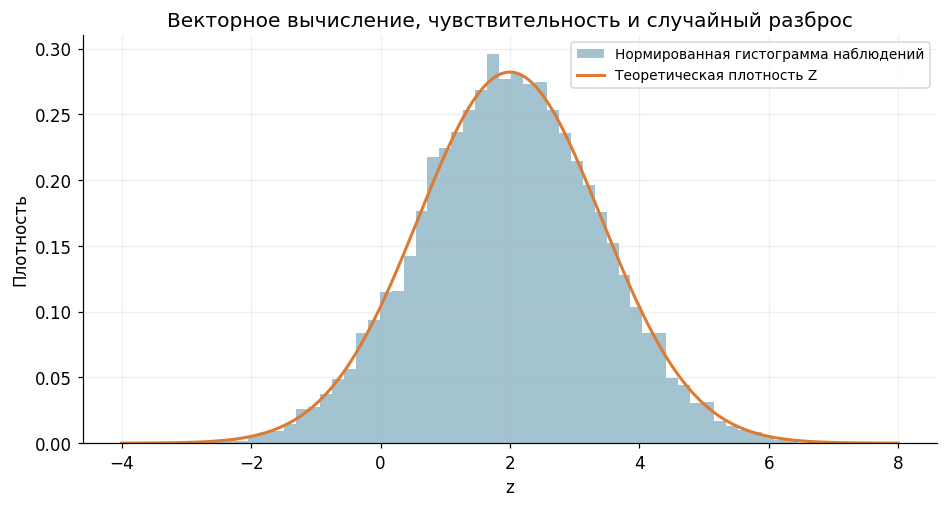

In [23]:
weights = np.array([2.0, -1.0])
input_means = np.array([3.0, 4.0])
input_stds = np.array([0.5, 1.0])
input_covariance = np.diag(input_stds ** 2)

theoretical_mean = weights @ input_means
theoretical_variance = weights @ input_covariance @ weights

combined_rng = np.random.default_rng(7)
input_observations = combined_rng.normal(
    loc=input_means, scale=input_stds, size=(20_000, 2)
)
linear_results = input_observations @ weights

print('Форма наблюдений:', input_observations.shape)
print(f'Ожидание по формуле: {theoretical_mean:.4f}; '
      f'среднее по выборке: {linear_results.mean():.4f}')
print(f'Дисперсия по формуле: {theoretical_variance:.4f}; '
      f'оценка по выборке: {linear_results.var(ddof=1):.4f}')
print('Градиент по входам:', weights)
print('Изменение z при Δx = (0,1; 0):', weights @ np.array([0.1, 0.0]))

result_grid = np.linspace(-4.0, 8.0, 400)
result_std = np.sqrt(theoretical_variance)
result_density = np.exp(-0.5 * ((result_grid - theoretical_mean) / result_std) ** 2)
result_density /= result_std * np.sqrt(2 * np.pi)

fig, ax = plt.subplots()
ax.hist(linear_results, bins=60, density=True, alpha=0.4,
        label='Нормированная гистограмма наблюдений')
ax.plot(result_grid, result_density, linewidth=2,
        label='Теоретическая плотность Z')
ax.set(xlabel='z', ylabel='Плотность',
       title='Векторное вычисление, чувствительность и случайный разброс')
ax.legend(fontsize=9)
plt.show()

**Разбор параметров и моделирования.**

- `weights`, `input_means`, `input_stds` — три массива из двух чисел: веса, ожидания, стандартные отклонения. Элементы с одним номером относятся к одному входу. Присваивание `=` сохраняет каждый массив под отдельным именем.
- `input_stds ** 2` возводит оба стандартных отклонения в квадрат. `np.diag(...)`, получив одномерный массив, ставит его элементы на диагональ новой квадратной матрицы, остальные места заполняет нулями. В `input_covariance` получается заданная матрица ковариаций независимых входов.
- `weights @ input_means` — скалярное произведение для ожидания. `weights @ input_covariance @ weights` — два последовательных матричных произведения для дисперсии. Одномерные массивы NumPy позволяют эту запись без явного `.T`; при ручной проверке формуле соответствует строка весов слева и столбец справа.
- `np.random.default_rng(7)` создаёт отдельный генератор с начальным значением 7. Его метод `.normal(...)` выдаёт нормальные значения: `loc` задаёт ожидания, `scale` — стандартные отклонения. Кортеж `size=(20_000, 2)` задаёт 20 000 строк и два столбца. Подчёркивание внутри числа только разделяет разряды.
- Массивы `loc` и `scale` содержат по два значения, поэтому каждая колонка использует свои параметры. `input_observations @ weights` применяет одну комбинацию к каждой строке и возвращает одномерный массив из 20 000 результатов.
- `.shape` показывает форму таблицы. `.mean()` вычисляет среднее массива результатов, `.var(ddof=1)` — выборочную оценку дисперсии с делителем $n-1$. Подстановки `f`-строк с `.4f` показывают эти числа рядом с теоретическими.
- `print('Градиент по входам:', weights)` выводит уже известный постоянный градиент: для линейной функции он равен весам. Выражение `weights @ np.array([0.1, 0.0])` считает изменение результата, когда первый вход вырос на 0,1, второй не изменился.

**Разбор гистограммы и плотности.**

- `result_grid = np.linspace(...)` создаёт сетку для теоретической линии. `np.sqrt(theoretical_variance)` находит стандартное отклонение. Функции `np.exp`, `np.sqrt` и константа `np.pi` собирают нормальную плотность так же, как в примере с одним распределением.
- Операция `/=` делит рассчитанную экспоненту на нормирующий множитель и сохраняет частное обратно в `result_density`. Математические степени здесь записываются `**`, обычные произведения — `*`.
- `ax.hist(linear_results, bins=60, density=True, alpha=0.4, ...)` разбивает значения на 60 интервалов и строит гистограмму. `density=True` нормирует **суммарную площадь** столбцов до 1, чтобы их высоты можно было сопоставить с плотностью. Это не означает, что сумма высот равна 1. `alpha` задаёт прозрачность, `label` — подпись.
- `ax.plot(result_grid, result_density, linewidth=2, ...)` добавляет теоретическую линию поверх гистограммы. `.set(...)` задаёт подписи, `.legend(fontsize=9)` показывает легенду заданного размера, `plt.show()` отображает рисунок.

Небольшие отличия выборочных оценок от 2 ожидаемы при конечном объёме данных. Значение изменения 0,2 согласуется с первой координатой градиента: $2\cdot0{,}1=0{,}2$.

`plt.subplots()` создаёт рисунок и одну область осей; два объекта распаковываются в `fig, ax`. Поэтому гистограмма `ax.hist(...)` и линия `ax.plot(...)` размещаются вместе и используют общие координаты.

Небольшое различие между теоретическими характеристиками и оценками по 20 000 наблюдений связано со случайностью конечной выборки. Теоретическое ожидание и дисперсия описывают заданное распределение, а среднее и выборочная дисперсия — конкретный смоделированный набор.

В примере одно выражение читается тремя способами: как скалярное произведение, как функция с градиентом и как случайная величина с распределением. Эти описания согласованы, но отвечают на разные вопросы: **что вычисляется**, **как результат меняется при изменении входов** и **каким бывает результат при случайных входах**.